# Assignment 4: Machine Learning Enhanced PCA Portfolio Construction
## Consumer Discretionary Sector | Group 8 | Spring 2026

**Analysis Period:** January 1, 2010 – May 1, 2026 &nbsp;|&nbsp; **Benchmark:** S&P 500 (^GSPC)

---

### Pipeline Overview

| # | Section | Method |
|---|---------|--------|
| 1 | Data Download & Preprocessing | Winsorize · Filter · Forward-fill |
| 2 | PCA Factor Decomposition | `sklearn.PCA` · Explained variance |
| 3 | Fundamental Screening | Compustat ratios · 4-step filter |
| 4 | Efficient Frontier Optimization | Monte Carlo · Min-volatility |
| 5 | ML Feature Engineering | Momentum · Vol · Fundamentals · PCA loadings |
| 6 | Walk-Forward RF Training | `RandomForestRegressor` · Expanding window CV |
| 7 | ML Portfolio Construction | Top-8 ranking · Min-vol weights |
| 8 | Feature Importance Analysis | Gini importance · IC / ICIR |
| 9 | Performance Comparison | Cumulative returns · Risk table · pyfolio |
| 10 | Academic Discussion | Methodology · Limitations · Conclusions |


In [22]:
import subprocess
import os

repo_path = '/content/repo'
repo_url = 'https://github.com/Shwee-ai/regression-forst.git'
branch_name = 'claude/review-consumer-discretionary-frXc2'

# Check if the repository already exists
if os.path.exists(repo_path):
    print(f"Repository already exists at {repo_path}. Pulling latest changes...")
    subprocess.run(['git', '-C', repo_path, 'pull'], check=True)
else:
    print(f"Cloning repository from {repo_url} (branch: {branch_name})...")
    subprocess.run(['git', 'clone', '--branch', branch_name, repo_url, repo_path], check=True)

os.chdir(repo_path)
print(f"✓ Repo ready at {repo_path}")
!ls *.ipynb

Repository already exists at /content/repo. Pulling latest changes...
✓ Repo ready at /content/repo
'Assignment_3_Consumer_Discretionary_Group8 (1) (1).ipynb'
 Assignment_4_Consumer_Discretionary_ML_Group8.ipynb
'Group8 assignemnt 1 (3).ipynb'
'Group 8 assignment 2 consumer discretionary.ipynb'


In [23]:
# ── Install / upgrade packages (safe to re-run) ───────────────────────────────
import subprocess, sys
_pkgs = ['yfinance --upgrade', 'pandas-datareader', 'pyfolio-reloaded']
for _p in _pkgs:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + _p.split(), check=False)
print("✓ Packages ready")


✓ Packages ready


In [24]:
# ── Standard library ─────────────────────────────────────────────────────────
import warnings, os
warnings.filterwarnings('ignore')

# ── Data / numerics ──────────────────────────────────────────────────────────
import pandas as pd
import numpy as np

# ── Finance data ─────────────────────────────────────────────────────────────
import yfinance as yf
import pandas_datareader.data as web

# ── Optimization & stats ─────────────────────────────────────────────────────
from scipy.stats.mstats import winsorize
from scipy.optimize import minimize
from scipy.stats import spearmanr

# ── Machine learning ─────────────────────────────────────────────────────────
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import r2_score

# ── Visualisation ────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.patches as mpatches
import seaborn as sns

# ── Performance analytics ─────────────────────────────────────────────────────
try:
    import pyfolio as pf
    PYFOLIO_AVAILABLE = True
except ImportError:
    PYFOLIO_AVAILABLE = False
    print("pyfolio not available – tear-sheet cells will show summary stats instead")

# ── Global style ─────────────────────────────────────────────────────────────
plt.style.use('dark_background')
PALETTE = ['#00d4ff', '#ff6b6b', '#ffd93d', '#6bcb77', '#a29bfe', '#fd79a8', '#e17055']
plt.rcParams.update({
    'figure.facecolor': '#0d1117', 'axes.facecolor': '#161b22',
    'axes.edgecolor': '#30363d',   'axes.labelcolor': '#c9d1d9',
    'xtick.color': '#8b949e',      'ytick.color': '#8b949e',
    'text.color': '#c9d1d9',       'grid.color': '#21262d', 'grid.alpha': 0.7,
    'legend.facecolor': '#161b22', 'legend.edgecolor': '#30363d',
    'figure.titlesize': 14,        'axes.titlesize': 12,
    'axes.labelsize': 10,          'xtick.labelsize': 9, 'ytick.labelsize': 9,
})

START  = '2010-01-01'
END    = '2026-05-01'
SECTOR = 'Consumer Discretionary'

print("✓ Environment ready")


✓ Environment ready


## Section 1 — Data Download & Preprocessing

In [25]:
# ── 1a  Fetch Consumer Discretionary tickers from Wikipedia ──────────────────
try:
    sp500_df = pd.read_html('https://en.wikipedia.org/wiki/List_of_S%26P_500_companies')[0]
    cd_tickers = (sp500_df[sp500_df['GICS Sector'] == SECTOR]['Symbol']
                  .str.replace('.', '-', regex=False).tolist())
    print(f"Fetched {len(cd_tickers)} Consumer Discretionary tickers from Wikipedia")
except Exception as e:
    # Fallback list based on known constituents
    cd_tickers = [
        'AMZN','APTV','AZO','BBY','BKNG','CCL','CMG','DECK','DHI','DPZ',
        'DRI','EBAY','EXPE','F','GM','GPC','GRMN','HAS','HD','HLT',
        'LEN','LOW','LULU','LVS','MAR','MCD','MGM','NCLH','NKE','NVR',
        'ORLY','PHM','POOL','RCL','RL','ROST','SBUX','TJX','TPR','TSCO',
        'TSLA','ULTA','WSM','WYNN','YUM'
    ]
    print(f"Wikipedia unavailable – using fallback list of {len(cd_tickers)} tickers")


Wikipedia unavailable – using fallback list of 45 tickers


In [26]:
# -- 1b  Download adjusted close prices
raw_prices = yf.download(cd_tickers, start=START, end=END,
                         auto_adjust=True, progress=False)['Close']
raw_prices = raw_prices.sort_index()
print(f"Downloaded: {raw_prices.shape[1]} tickers x {raw_prices.shape[0]} trading days")

# -- 1c  Daily simple returns
returns_raw = raw_prices.pct_change()
returns_raw = returns_raw.iloc[1:]           # drop first NaN row

# -- 1d  Winsorise FIRST to [5th, 95th] percentile (per assignment instructions)
#        scipy.stats.mstats.winsorize handles NaN safely via masked arrays.
def winsorise_col(col):
    arr = winsorize(col.values, limits=[0.05, 0.05])
    return pd.Series(arr, index=col.index)

returns_wins = returns_raw.apply(winsorise_col)
print(f"After winsorisation : {returns_wins.shape[1]} stocks x {returns_wins.shape[0]} days")

# -- 1e  Remove stocks with <95% data completeness
completeness = returns_wins.notna().mean()
keep_stocks  = completeness[completeness >= 0.95].index
returns_wins = returns_wins[keep_stocks]
print(f"After stock filter  : {len(keep_stocks)} stocks")

# -- 1f  Remove trading days where <95% of stocks have data
day_coverage = returns_wins.notna().mean(axis=1)
returns_wins = returns_wins.loc[day_coverage >= 0.95]
print(f"After day filter    : {len(returns_wins)} trading days")

# -- 1g  Fill remaining NaN with cross-sectional daily mean
daily_mean    = returns_wins.mean(axis=1)
returns_clean = returns_wins.apply(lambda col: col.fillna(daily_mean))
print(f"Final return matrix : {returns_clean.shape[0]} days x {returns_clean.shape[1]} stocks")
returns_clean.describe().round(4)


Downloaded: 45 tickers x 4106 trading days
After winsorisation : 45 stocks x 4105 days
After stock filter  : 41 stocks
After day filter    : 4105 trading days
Final return matrix : 4105 days x 41 stocks


Ticker,AMZN,AZO,BBY,BKNG,CCL,CMG,DECK,DHI,DPZ,DRI,...,ROST,SBUX,TJX,TPR,TSCO,TSLA,ULTA,WSM,WYNN,YUM
count,4105.0000,4105.0000,4105.0000,4105.0000,4105.0000,4105.0000,4105.0000,4105.0000,4105.0000,4105.0000,...,4105.0000,4105.0000,4105.0000,4105.0000,4105.0000,4105.0000,4105.0000,4105.0000,4105.0000,4105.0000
mean,0.0010,0.0011,0.0006,0.0009,0.0004,0.0008,0.0011,0.0008,0.0011,0.0008,...,0.0009,0.0006,0.0008,0.0009,0.0008,0.0049,0.0008,0.0010,0.0003,0.0007
std,0.0159,0.0111,0.0177,0.0154,0.0205,0.0154,0.0203,0.0183,0.0140,0.0132,...,0.0130,0.0127,0.0116,0.0179,0.0143,0.0323,0.0166,0.0186,0.0215,0.0109
min,-0.0301,-0.0198,-0.0341,-0.0293,-0.0420,-0.0298,-0.0379,-0.0337,-0.0259,-0.0245,...,-0.0244,-0.0244,-0.0212,-0.0335,-0.0272,-0.0509,-0.0315,-0.0343,-0.0407,-0.0208
25%,-0.0091,-0.0064,-0.0113,-0.0090,-0.0112,-0.0091,-0.0126,-0.0114,-0.0077,-0.0076,...,-0.0076,-0.0077,-0.0069,-0.0108,-0.0085,-0.0158,-0.0100,-0.0113,-0.0131,-0.0063
50%,0.0010,0.0007,0.0007,0.0008,0.0005,0.0008,0.0013,0.0006,0.0010,0.0006,...,0.0007,0.0006,0.0007,0.0008,0.0009,0.0018,0.0006,0.0006,-0.0002,0.0008
75%,0.0120,0.0085,0.0132,0.0108,0.0118,0.0108,0.0149,0.0125,0.0099,0.0093,...,0.0093,0.0090,0.0085,0.0122,0.0105,0.0219,0.0115,0.0130,0.0136,0.0077
max,0.0315,0.0225,0.0333,0.0307,0.0430,0.0300,0.0401,0.0360,0.0286,0.0268,...,0.0264,0.0257,0.0236,0.0360,0.0274,0.0822,0.0331,0.0374,0.0438,0.0213


## Section 2 — Principal Component Analysis

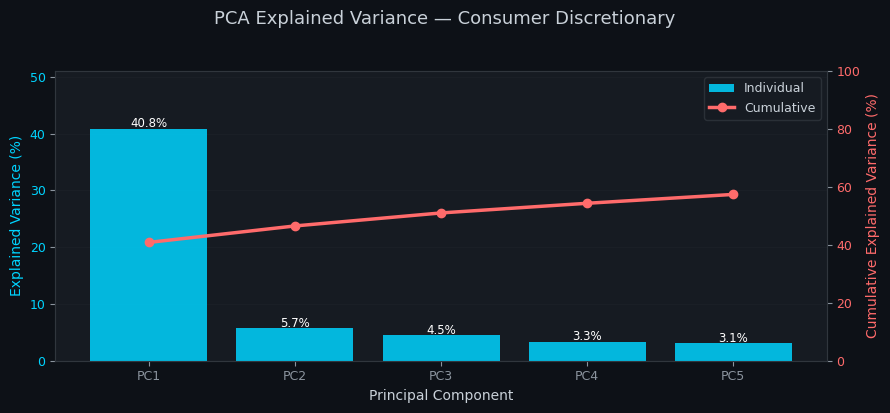

PC1 alone explains 40.8% of sector variance
First 5 PCs explain 57.4% of sector variance


In [27]:
# ── 2a  Standardise and fit PCA ──────────────────────────────────────────────
scaler_pca = StandardScaler()
X_scaled   = scaler_pca.fit_transform(returns_clean)   # shape: (T, N)

n_components = min(returns_clean.shape[1], 20)
pca_model    = PCA(n_components=n_components)
pca_model.fit(X_scaled)

expl_var     = pca_model.explained_variance_ratio_
cum_var      = np.cumsum(expl_var)

# ── 2b  Explained variance plot (first 5 PCs) ────────────────────────────────
fig, ax1 = plt.subplots(figsize=(9, 4))

bars = ax1.bar(range(1, 6), expl_var[:5]*100, color=PALETTE[0], alpha=0.85,
               label='Individual', zorder=3)
ax1.set_xlabel('Principal Component'); ax1.set_ylabel('Explained Variance (%)', color=PALETTE[0])
ax1.tick_params(axis='y', labelcolor=PALETTE[0])
ax1.set_xticks(range(1, 6)); ax1.set_xticklabels([f'PC{i}' for i in range(1,6)])
ax1.set_ylim(0, expl_var[:5].max()*100*1.25)
ax1.grid(axis='y', alpha=0.4)

ax2 = ax1.twinx()
ax2.plot(range(1, 6), cum_var[:5]*100, color=PALETTE[1], marker='o',
         linewidth=2.5, label='Cumulative', zorder=4)
ax2.set_ylabel('Cumulative Explained Variance (%)', color=PALETTE[1])
ax2.tick_params(axis='y', labelcolor=PALETTE[1])
ax2.set_ylim(0, 100)

for i, v in enumerate(expl_var[:5]):
    ax1.text(i+1, v*100 + 0.3, f'{v*100:.1f}%', ha='center', fontsize=8.5, color='white')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1+lines2, labels1+labels2, loc='upper right', fontsize=9)

fig.suptitle('PCA Explained Variance — Consumer Discretionary', y=1.02, fontsize=13)
fig.tight_layout(); plt.show()

print(f"PC1 alone explains {expl_var[0]*100:.1f}% of sector variance")
print(f"First 5 PCs explain {cum_var[4]*100:.1f}% of sector variance")


PC_Large (highest PC1 loadings): ['HD', 'MAR', 'GPC', 'LOW', 'NKE', 'ROST', 'TJX', 'MGM', 'RL', 'SBUX']

PC_Small (lowest PC1 loadings) : ['WYNN', 'HAS', 'AMZN', 'EBAY', 'ORLY', 'CMG', 'MCD', 'AZO', 'DPZ', 'TSLA']


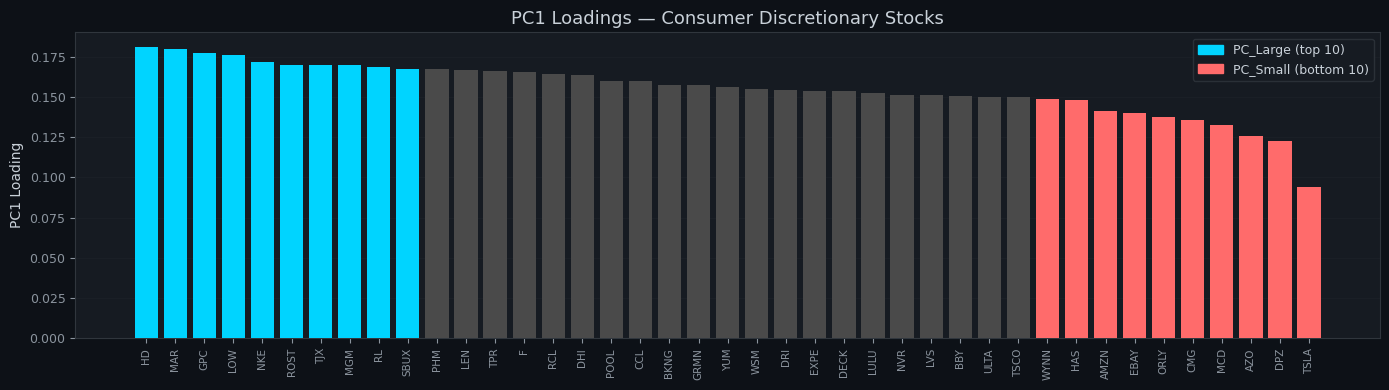

In [28]:
# ── 2c  PC_Large (top 10) and PC_Small (bottom 10) by PC1 loading ────────────
pc1_loadings = pd.Series(pca_model.components_[0], index=returns_clean.columns)
pc1_sorted   = pc1_loadings.sort_values(ascending=False)

PC_Large = pc1_sorted.head(10).index.tolist()
PC_Small = pc1_sorted.tail(10).index.tolist()

print("PC_Large (highest PC1 loadings):", PC_Large)
print()
print("PC_Small (lowest PC1 loadings) :", PC_Small)

# Loadings bar chart
fig, ax = plt.subplots(figsize=(14, 4))
colors = [PALETTE[0] if t in PC_Large else PALETTE[1] if t in PC_Small else '#4a4a4a'
          for t in pc1_sorted.index]
ax.bar(range(len(pc1_sorted)), pc1_sorted.values, color=colors, zorder=3)
ax.axhline(0, color='white', linewidth=0.7)
ax.set_xticks(range(len(pc1_sorted)))
ax.set_xticklabels(pc1_sorted.index, rotation=90, fontsize=7.5)
ax.set_title('PC1 Loadings — Consumer Discretionary Stocks', fontsize=13)
ax.set_ylabel('PC1 Loading')
ax.grid(axis='y', alpha=0.4)
patches = [mpatches.Patch(color=PALETTE[0], label='PC_Large (top 10)'),
           mpatches.Patch(color=PALETTE[1], label='PC_Small (bottom 10)')]
ax.legend(handles=patches, fontsize=9)
fig.tight_layout(); plt.show()


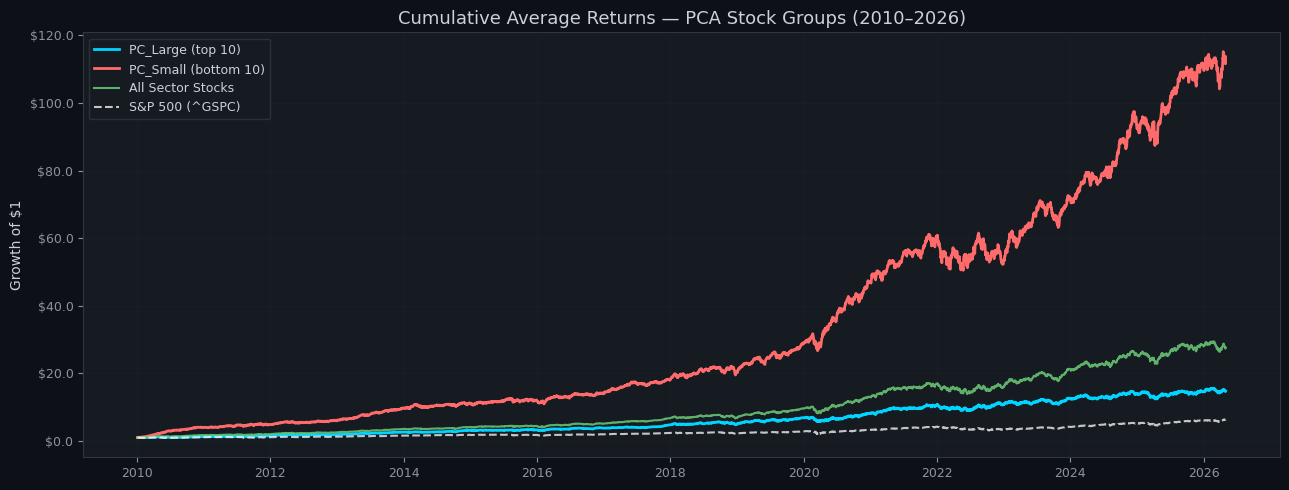

In [29]:
# ── 2d  Cumulative average returns: PC_Large vs PC_Small vs All vs S&P500 ─────
sp500_prices = yf.download('^GSPC', start=START, end=END,
                           auto_adjust=True, progress=False)['Close'].squeeze()
sp500_ret = sp500_prices.pct_change().iloc[1:]
sp500_ret = sp500_ret.reindex(returns_clean.index).fillna(0)

cum_large = (1 + returns_clean[PC_Large].mean(axis=1)).cumprod()
cum_small = (1 + returns_clean[PC_Small].mean(axis=1)).cumprod()
cum_all   = (1 + returns_clean.mean(axis=1)).cumprod()
cum_sp500 = (1 + sp500_ret.squeeze()).cumprod()

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(cum_large.index, cum_large.values, color=PALETTE[0], lw=2,   label='PC_Large (top 10)')
ax.plot(cum_small.index, cum_small.values, color=PALETTE[1], lw=2,   label='PC_Small (bottom 10)')
ax.plot(cum_all.index,   cum_all.values,   color=PALETTE[3], lw=1.5, label='All Sector Stocks', alpha=0.85)
ax.plot(cum_sp500.index, cum_sp500.values, color='white',    lw=1.5, label='S&P 500 (^GSPC)', alpha=0.75, ls='--')
ax.set_title('Cumulative Average Returns — PCA Stock Groups (2010–2026)', fontsize=13)
ax.set_ylabel('Growth of $1')
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.1f}'))
ax.legend(fontsize=9); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()


## Section 3 -- Financial Statement Analysis

> **Data source:** `funda_sp.csv` -- Compustat annual fundamentals file provided in the course Google Drive.  
> Upload `funda_sp.csv` to Colab (Files panel or Drive) before running this section.
>
> **Compustat columns used (per assignment specification):**
> - `current_ratio` = `act` / `dlc`
> - `debt_ratio`    = (`dlc` + `dltt`) / `at`
> - `profit_margin` = `ni` / `sale`
> - `roa`           = `ni` / `at`
>
> Fiscal year (`fyear`) is mapped to Dec 31 of that year as the `datadate` for time-series alignment.


In [31]:
# -- 3a  Load funda_sp (Compustat annual fundamentals — course-provided file)
#
# Upload funda_sp.csv to Colab via one of:
#   Option A: Files panel -> Upload -> select funda_sp.csv
#   Option B: from google.colab import drive; drive.mount('/content/drive')
#             then set FUNDA_PATH to the Drive location
#
# Known columns: Unnamed:0, gvkey, conm, tic, sich, fyear, at, act, dlc, dltt, sale, ni, prcc_f, csho
# The date dimension is 'fyear' (integer fiscal year, e.g. 2015).

FUNDA_PATH = '/content/funda_sp.csv'   # <- change to '/content/drive/MyDrive/funda_sp.csv' if using Drive

funda_raw = pd.read_csv(FUNDA_PATH, low_memory=False)

# -- Drop unnamed index column if present
funda_raw = funda_raw.loc[:, ~funda_raw.columns.str.startswith('Unnamed')]

# -- Normalise ticker: Compustat uses '.' (BRK.B, BF.B); yfinance/Wikipedia use '-'
funda_raw['tic'] = funda_raw['tic'].str.strip().str.replace('.', '-', regex=False)

# -- Ensure fyear is integer and numeric columns are float
funda_raw['fyear'] = pd.to_numeric(funda_raw['fyear'], errors='coerce').astype('Int64')
for col in ['at', 'act', 'dlc', 'dltt', 'sale', 'ni']:
    funda_raw[col] = pd.to_numeric(funda_raw[col], errors='coerce')

funda_raw = funda_raw.sort_values(['tic', 'fyear']).reset_index(drop=True)

print(f"funda_sp loaded: {len(funda_raw):,} rows | {funda_raw['tic'].nunique()} tickers")
print(f"Fiscal years   : {int(funda_raw['fyear'].min())} - {int(funda_raw['fyear'].max())}")
print(funda_raw[['tic','fyear','at','act','dlc','dltt','sale','ni']].head(5).to_string(index=False))


funda_sp loaded: 9,125 rows | 500 tickers
Fiscal years   : 2009 - 2025
tic  fyear      at    act    dlc   dltt   sale     ni
  A   2010  9696.0 6169.0 1501.0 2190.0 5463.0  684.0
  A   2011  9057.0 5569.0  253.0 1932.0 6626.0 1012.0
  A   2012 10536.0 4629.0  250.0 2112.0 6858.0 1153.0
  A   2013 10686.0 4983.0    0.0 2699.0 6782.0  724.0
  A   2014 10831.0 5500.0    0.0 2762.0 6981.0  504.0


In [33]:
# -- 3b  Compute ratios using exact Compustat column names from assignment
funda_all = funda_raw.copy()
funda_all = funda_all.sort_values(['tic', 'fyear'])

funda_all['current_ratio'] = funda_all['act'] / funda_all['dlc'].replace(0, np.nan)
funda_all['debt_ratio']    = (
    funda_all['dlc'].fillna(0) + funda_all['dltt'].fillna(0)
) / funda_all['at'].replace(0, np.nan)
funda_all['profit_margin'] = funda_all['ni']   / funda_all['sale'].replace(0, np.nan)
funda_all['roa']           = funda_all['ni']   / funda_all['at'].replace(0, np.nan)

# -- 3c  3-year moving average per ticker (sorted by fyear)
for ratio in ['current_ratio', 'debt_ratio', 'profit_margin', 'roa']:
    funda_all[f'{ratio}_ma3'] = (
        funda_all.groupby('tic')[ratio]
        .transform(lambda x: x.rolling(3, min_periods=1).mean())
    )

# -- 3d  Add fiscal-year-end date column (Dec 31 of fyear) for time-series joins
funda_all['datadate'] = pd.to_datetime(
    funda_all['fyear'].astype(str) + '-12-31', errors='coerce'
)

# -- 3e  Filter to PC stocks and keep only the most recent fiscal year per ticker
all_pca_stocks = list(set(PC_Large + PC_Small))
funda          = funda_all[funda_all['tic'].isin(all_pca_stocks)].copy()
latest_funda   = funda.sort_values('fyear').groupby('tic').tail(1).set_index('tic')
print(f"Latest fundamental data: {latest_funda.shape[0]} stocks")
latest_funda[['fyear','roa_ma3','current_ratio_ma3','profit_margin_ma3','debt_ratio_ma3']].round(4)


Latest fundamental data: 20 stocks


,fyear,roa_ma3,current_ratio_ma3,profit_margin_ma3,debt_ratio_ma3
tic,,,,,
NKE,2024,0.1242,40.5558,0.0932,0.3128
RL,2024,0.0934,10.0482,0.0945,0.4028
ROST,2025,0.1364,6.5077,0.0951,0.3728
AMZN,2025,0.0825,10.8928,0.0847,0.2578
MAR,2025,0.1017,3.4128,0.1080,0.5704
SBUX,2025,0.1060,2.4233,0.0895,0.8300
MCD,2025,0.1479,5.3341,0.3226,0.9360
MGM,2025,0.0166,35.7920,0.0420,0.7546
WYNN,2025,0.0386,33.0207,0.0760,0.9472


In [34]:
# ── 3e  4-step screening function ────────────────────────────────────────────
def screen_4_stocks(group_tickers, funda_df, label):
    """Apply the 4-step assignment screening and return 4 selected tickers."""
    df = funda_df.loc[funda_df.index.isin(group_tickers)].copy()
    df = df.dropna(subset=['roa_ma3','current_ratio_ma3','profit_margin_ma3','debt_ratio_ma3'])

    step1 = df.nlargest(8,  'roa_ma3')           # top 8 by ROA
    step2 = step1.nlargest(6, 'current_ratio_ma3')# top 6 by current ratio
    step3 = step2.nlargest(5, 'profit_margin_ma3')# top 5 by profit margin
    step4 = step3.nsmallest(4, 'debt_ratio_ma3')  # bottom 4 by debt ratio

    selected = step4.index.tolist()
    print(f"\n{label} screening steps:")
    print(f"  Start → {len(df)} stocks")
    print(f"  Step 1 (top-8 ROA)         → {step1.index.tolist()}")
    print(f"  Step 2 (top-6 curr_ratio)  → {step2.index.tolist()}")
    print(f"  Step 3 (top-5 prof_margin) → {step3.index.tolist()}")
    print(f"  Step 4 (low-4 debt_ratio)  → {selected}")
    return selected

PC_Large_4 = screen_4_stocks(PC_Large, latest_funda, 'PC_Large')
PC_Small_4 = screen_4_stocks(PC_Small, latest_funda, 'PC_Small')



PC_Large screening steps:
  Start → 10 stocks
  Step 1 (top-8 ROA)         → ['HD', 'LOW', 'TJX', 'ROST', 'NKE', 'SBUX', 'MAR', 'RL']
  Step 2 (top-6 curr_ratio)  → ['NKE', 'LOW', 'RL', 'TJX', 'HD', 'ROST']
  Step 3 (top-5 prof_margin) → ['ROST', 'RL', 'NKE', 'HD', 'TJX']
  Step 4 (low-4 debt_ratio)  → ['NKE', 'ROST', 'TJX', 'RL']

PC_Small screening steps:
  Start → 10 stocks
  Step 1 (top-8 ROA)         → ['DPZ', 'CMG', 'ORLY', 'MCD', 'AZO', 'EBAY', 'AMZN', 'TSLA']
  Step 2 (top-6 curr_ratio)  → ['TSLA', 'AZO', 'ORLY', 'AMZN', 'DPZ', 'EBAY']
  Step 3 (top-5 prof_margin) → ['EBAY', 'ORLY', 'AZO', 'DPZ', 'TSLA']
  Step 4 (low-4 debt_ratio)  → ['TSLA', 'EBAY', 'ORLY', 'AZO']


In [35]:
# ── 3f  Ratios summary table for selected stocks ─────────────────────────────
selected_all = PC_Large_4 + PC_Small_4
display_cols = ['current_ratio_ma3','debt_ratio_ma3','profit_margin_ma3','roa_ma3']
ratio_table  = latest_funda.loc[[t for t in selected_all if t in latest_funda.index], display_cols]
ratio_table.columns = ['Current Ratio (3yr MA)', 'Debt Ratio (3yr MA)',
                        'Profit Margin (3yr MA)', 'ROA (3yr MA)']
ratio_table.index.name = 'Ticker'
print("Financial ratios for selected stocks:")
print(ratio_table.round(4).to_string())


Financial ratios for selected stocks:
        Current Ratio (3yr MA)  Debt Ratio (3yr MA)  Profit Margin (3yr MA)  ROA (3yr MA)
Ticker                                                                                   
NKE                    40.5558               0.3128                  0.0932        0.1242
ROST                    6.5077               0.3728                  0.0951        0.1364
TJX                     7.1122               0.4004                  0.0866        0.1524
RL                     10.0482               0.4028                  0.0945        0.0934
TSLA                   20.2138               0.1027                  0.0892        0.0754
EBAY                    7.5897               0.3981                  0.2162        0.1151
ORLY                   14.5103               0.5368                  0.1447        0.1610
AZO                    19.9725               0.6942                  0.1402        0.1474


## Section 4 — Efficient Frontier Portfolio Optimization

In [36]:
# ── 4a  Efficient Frontier helper ────────────────────────────────────────────
def run_ef(tickers, daily_ret, rf_rate_series, n_portfolios=100_000, n_frontier=200,
           label='Portfolio'):
    """Monte Carlo EF + min-volatility optimisation. Returns weights & metrics."""
    stocks = [t for t in tickers if t in daily_ret.columns]
    ret    = daily_ret[stocks].dropna()

    mean_a = ret.mean() * 252
    cov_a  = ret.cov()  * 252
    rf_ann = rf_rate_series.reindex(ret.index, method='ffill').mean() * 252

    n = len(stocks)
    np.random.seed(42)
    sim_ret = np.zeros(n_portfolios); sim_vol = np.zeros(n_portfolios)
    sim_sr  = np.zeros(n_portfolios)

    for i in range(n_portfolios):
        w     = np.random.dirichlet(np.ones(n))
        p_r   = float(mean_a.values @ w)
        p_v   = float(np.sqrt(w @ cov_a.values @ w))
        sim_ret[i] = p_r; sim_vol[i] = p_v
        sim_sr[i]  = (p_r - rf_ann) / p_v

    # Efficient frontier via constrained optimisation
    ret_range = np.linspace(sim_ret.min(), sim_ret.max(), n_frontier)
    ef_vols, ef_rets = [], []
    for tgt in ret_range:
        res = minimize(
            lambda w: float(np.sqrt(w @ cov_a.values @ w)),
            np.ones(n)/n, method='SLSQP',
            bounds=[(0, 1)]*n,
            constraints=[{'type':'eq','fun': lambda w: w.sum()-1},
                         {'type':'eq','fun': lambda w, r=tgt: float(mean_a.values @ w)-r}]
        )
        if res.success:
            ef_vols.append(res.fun); ef_rets.append(tgt)

    # Global minimum volatility
    res_min = minimize(
        lambda w: float(np.sqrt(w @ cov_a.values @ w)),
        np.ones(n)/n, method='SLSQP',
        bounds=[(0, 1)]*n,
        constraints=[{'type':'eq','fun': lambda w: w.sum()-1}]
    )
    opt_w  = pd.Series(res_min.x, index=stocks)
    opt_r  = float(mean_a.values @ res_min.x)
    opt_v  = res_min.fun
    opt_sr = (opt_r - rf_ann) / opt_v

    eq_w   = pd.Series(np.ones(n)/n, index=stocks)
    eq_r   = float(mean_a.values @ eq_w.values)
    eq_v   = float(np.sqrt(eq_w.values @ cov_a.values @ eq_w.values))

    # Plot
    fig, ax = plt.subplots(figsize=(10, 6))
    sc = ax.scatter(sim_vol*100, sim_ret*100, c=sim_sr, cmap='plasma',
                    s=1, alpha=0.3, zorder=1)
    plt.colorbar(sc, ax=ax, label='Sharpe Ratio')
    ax.plot(np.array(ef_vols)*100, np.array(ef_rets)*100,
            color='white', lw=2.5, label='Efficient Frontier', zorder=3)
    ax.scatter([opt_v*100], [opt_r*100], color=PALETTE[0], s=160, zorder=5,
               marker='*', label=f'Optimal (Sharpe {opt_sr:.2f})')
    ax.scatter([eq_v*100],  [eq_r*100],  color=PALETTE[1], s=100, zorder=5,
               marker='D', label='Equal Weight')
    ax.set_xlabel('Annualised Volatility (%)'); ax.set_ylabel('Annualised Return (%)')
    ax.set_title(f'Efficient Frontier — {label}', fontsize=13)
    ax.legend(fontsize=9); ax.grid(alpha=0.3)
    fig.tight_layout(); plt.show()

    print(f"\n{label} — Optimal portfolio")
    print(f"  Weights : {opt_w.round(4).to_dict()}")
    print(f"  Return  : {opt_r*100:.2f}%  |  Vol: {opt_v*100:.2f}%  |  Sharpe: {opt_sr:.3f}")

    return {
        'stocks': stocks, 'opt_weights': opt_w, 'eq_weights': eq_w,
        'opt_return': opt_r, 'opt_vol': opt_v, 'opt_sharpe': opt_sr,
        'eq_return': eq_r,   'eq_vol': eq_v,   'rf': rf_ann,
        'mean_annual': mean_a, 'cov_annual': cov_a,
    }

# ── Download risk-free rate (TB3MS) ──────────────────────────────────────────
tb3ms  = web.DataReader('TB3MS', 'fred', START, END)
rf_raw = tb3ms['TB3MS'] / 100 / 252          # daily decimal
rf_raw = rf_raw.reindex(returns_clean.index, method='ffill').bfill()
print("Risk-free rate loaded. Mean daily RF:", rf_raw.mean().round(6))


Risk-free rate loaded. Mean daily RF: 5.7e-05


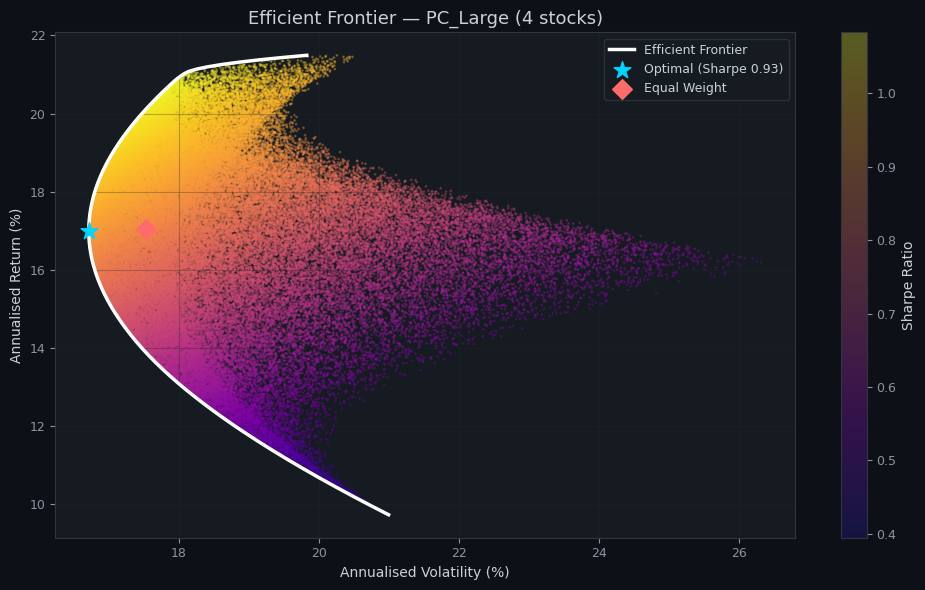


PC_Large (4 stocks) — Optimal portfolio
  Weights : {'NKE': 0.3335, 'ROST': 0.1306, 'TJX': 0.5046, 'RL': 0.0313}
  Return  : 16.99%  |  Vol: 16.72%  |  Sharpe: 0.931


In [37]:
# ── 4b  PC_Large Efficient Frontier ──────────────────────────────────────────
ef_large = run_ef(PC_Large_4, returns_clean, rf_raw, label='PC_Large (4 stocks)')


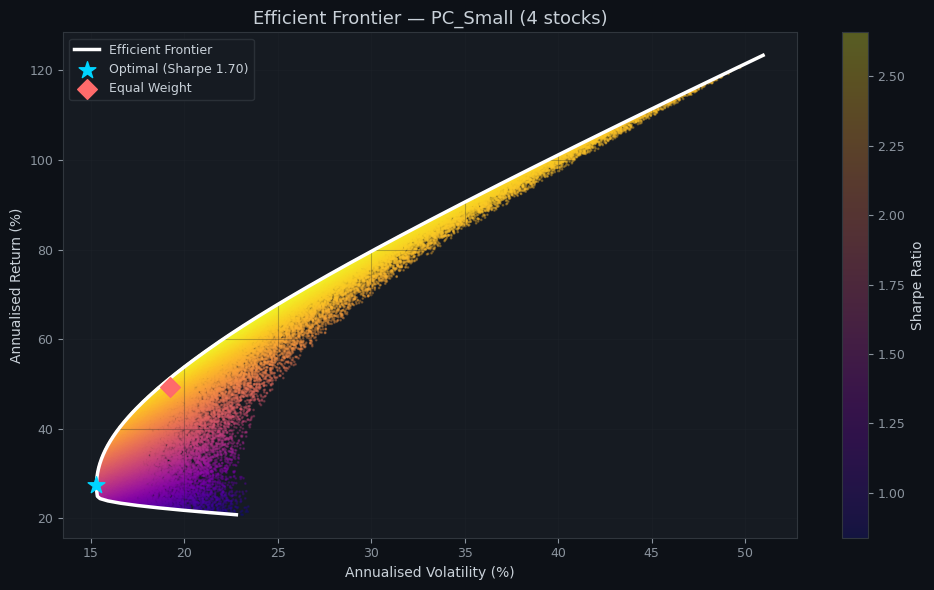


PC_Small (4 stocks) — Optimal portfolio
  Weights : {'TSLA': 0.0246, 'EBAY': 0.2472, 'ORLY': 0.2873, 'AZO': 0.4408}
  Return  : 27.42%  |  Vol: 15.29%  |  Sharpe: 1.699


In [38]:
# ── 4c  PC_Small Efficient Frontier ──────────────────────────────────────────
ef_small = run_ef(PC_Small_4, returns_clean, rf_raw, label='PC_Small (4 stocks)')


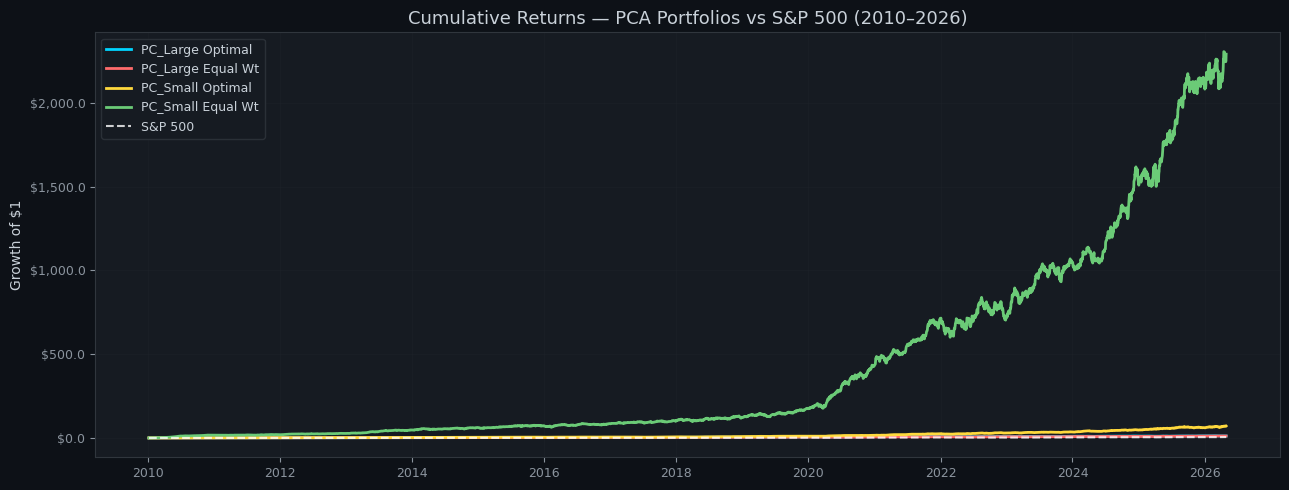

In [39]:
# ── 4d  Compute daily portfolio returns for all 4 base portfolios ─────────────
def port_returns(daily_ret, weights):
    stocks = weights.index.tolist()
    avail  = [s for s in stocks if s in daily_ret.columns]
    return (daily_ret[avail] * weights[avail].values).sum(axis=1)

ret_large_opt = port_returns(returns_clean, ef_large['opt_weights'])
ret_large_eq  = port_returns(returns_clean, ef_large['eq_weights'])
ret_small_opt = port_returns(returns_clean, ef_small['opt_weights'])
ret_small_eq  = port_returns(returns_clean, ef_small['eq_weights'])

# ── 4e  Portfolio comparison chart (4 portfolios) ─────────────────────────────
cum = {
    'PC_Large Optimal' : (1 + ret_large_opt).cumprod(),
    'PC_Large Equal Wt': (1 + ret_large_eq ).cumprod(),
    'PC_Small Optimal' : (1 + ret_small_opt).cumprod(),
    'PC_Small Equal Wt': (1 + ret_small_eq ).cumprod(),
}

fig, ax = plt.subplots(figsize=(13, 5))
for i, (name, series) in enumerate(cum.items()):
    ax.plot(series.index, series.values, color=PALETTE[i], lw=2, label=name)
sp500_aligned = sp500_ret.reindex(ret_large_opt.index).fillna(0)
ax.plot((1 + sp500_aligned.squeeze()).cumprod().index,
        (1 + sp500_aligned.squeeze()).cumprod().values,
        color='white', lw=1.5, ls='--', label='S&P 500', alpha=0.8)
ax.set_title('Cumulative Returns — PCA Portfolios vs S&P 500 (2010–2026)', fontsize=13)
ax.set_ylabel('Growth of $1')
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.1f}'))
ax.legend(fontsize=9); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()


## Section 5 — ML Feature Engineering

We build a monthly panel `(date × ticker)` where **every feature at month t uses only data available strictly before the start of month t+1**. This strict temporal ordering prevents any lookahead bias.

| Feature Group | Features | Rationale |
|---|---|---|
| Momentum | 1m / 3m / 6m / 12m-skip-1 returns | Jegadeesh-Titman (1993) |
| Volatility | Realised vol (1m/3m/6m), vol-ratio | Ang et al. (2006) |
| Risk-adjusted | Rolling Sharpe (3m/6m/12m), Sortino (6m) | Quality signal |
| Relative strength | Excess return vs sector mean (1m/3m) | Sector momentum |
| PCA loadings | PC1–PC3 loadings, is_pc_large flag | Factor exposure |
| Fundamentals | ROA, curr_ratio, prof_margin, debt_ratio (3yr MA + trend) | Fama-French quality |
| Macro | Risk-free rate level & change, S&P 500 momentum & vol | Regime awareness |


In [40]:
# ── 5a  Monthly returns and excess returns ───────────────────────────────────
monthly_ret = returns_clean.resample('ME').apply(lambda x: (1+x).prod() - 1)
rf_monthly  = rf_raw.resample('ME').last() * 21   # approx monthly RF
exc_ret     = monthly_ret.subtract(rf_monthly, axis=0)

# ── 5b  Momentum features ────────────────────────────────────────────────────
def compound_ret(df, n):
    return df.rolling(n).apply(lambda x: (1+x).prod()-1, raw=True)

feat = {}
feat['mom_1m']        = monthly_ret.copy()
feat['mom_3m']        = compound_ret(monthly_ret, 3)
feat['mom_6m']        = compound_ret(monthly_ret, 6)
feat['mom_12m_skip1'] = compound_ret(monthly_ret.shift(1), 11)  # skip most recent month

# ── 5c  Volatility features (from daily data resampled) ──────────────────────
daily_vol_m     = returns_clean.resample('ME').std() * np.sqrt(252)
feat['vol_1m']  = daily_vol_m.copy()
feat['vol_3m']  = daily_vol_m.rolling(3).mean()
feat['vol_6m']  = daily_vol_m.rolling(6).mean()
feat['vol_ratio']= feat['vol_1m'] / feat['vol_6m'].replace(0, np.nan)

# ── 5d  Rolling Sharpe & Sortino ─────────────────────────────────────────────
def roll_sharpe(df, n):
    return (df.rolling(n).mean() / df.rolling(n).std()) * np.sqrt(12)

feat['sharpe_3m']  = roll_sharpe(exc_ret, 3)
feat['sharpe_6m']  = roll_sharpe(exc_ret, 6)
feat['sharpe_12m'] = roll_sharpe(exc_ret, 12)

def roll_sortino(df, n):
    neg   = df.where(df < 0).rolling(n).std() * np.sqrt(12)
    return (df.rolling(n).mean() * 12) / neg.replace(0, np.nan)

feat['sortino_6m'] = roll_sortino(exc_ret, 6)

# ── 5e  Relative strength vs sector average ──────────────────────────────────
sect_mean_1m = monthly_ret.mean(axis=1)
sect_mean_3m = compound_ret(monthly_ret.mean(axis=1).to_frame('s'), 3)['s']
feat['rel_strength_1m'] = monthly_ret.subtract(sect_mean_1m, axis=0)
feat['rel_strength_3m'] = compound_ret(monthly_ret, 3).subtract(sect_mean_3m, axis=0)

print(f"Technical features built. Panel shape: {monthly_ret.shape}")


Technical features built. Panel shape: (196, 41)


In [41]:
# ── 5f  PCA-based features ────────────────────────────────────────────────────
pca_load_df = pd.DataFrame(
    pca_model.components_[:3].T,
    index=returns_clean.columns,
    columns=['pc1_loading', 'pc2_loading', 'pc3_loading']
)
pca_load_df['is_pc_large'] = pca_load_df.index.isin(PC_Large).astype(int)

# ── 5g  Macro features ────────────────────────────────────────────────────────
rf_m = rf_monthly.reindex(monthly_ret.index, method='ffill')
feat['rf_rate']       = pd.DataFrame({t: rf_m for t in monthly_ret.columns})
feat['rf_change_3m']  = feat['rf_rate'] - feat['rf_rate'].shift(3)

sp500_m = sp500_ret.squeeze().resample('ME').apply(lambda x: (1+x).prod()-1)
sp500_m = sp500_m.reindex(monthly_ret.index, method='ffill')
feat['sp500_ret_1m'] = pd.DataFrame({t: sp500_m for t in monthly_ret.columns})
feat['sp500_ret_3m'] = pd.DataFrame({t: compound_ret(sp500_m.to_frame('s'), 3)['s']
                                     for t in monthly_ret.columns})
sp500_vol_3m = sp500_m.rolling(3).std() * np.sqrt(12)
feat['sp500_vol_3m'] = pd.DataFrame({t: sp500_vol_3m for t in monthly_ret.columns})
feat['sector_mom_3m']= pd.DataFrame({t: compound_ret(monthly_ret.mean(axis=1).to_frame('s'), 3)['s']
                                      for t in monthly_ret.columns})

# ── 5h  Stack into long panel ────────────────────────────────────────────────
panel_dfs = []
for name, wide in feat.items():
    long = wide.stack().rename(name)
    panel_dfs.append(long)

panel = pd.concat(panel_dfs, axis=1)
panel.index.names = ['date', 'ticker']

# Add PCA loadings (constant per ticker)
panel = panel.reset_index()
pca_load_df.index.name = 'ticker'
panel = panel.merge(pca_load_df.reset_index(),
                    on='ticker', how='left')
panel = panel.set_index(['date', 'ticker']).sort_index()

print(f"Panel shape: {panel.shape}  | Features: {panel.shape[1]}")


Panel shape: (8036, 24)  | Features: 24


In [42]:
# -- 5i  Fundamental features (lagged 3 months to avoid lookahead)
#        funda_all['datadate'] = Dec 31 of fyear; 3-month lag => effective Apr 1 of fyear+1
fund_ratio_cols = ['current_ratio_ma3', 'debt_ratio_ma3', 'profit_margin_ma3',
                   'roa_ma3', 'current_ratio', 'debt_ratio', 'profit_margin', 'roa']


def build_fund_panel(funda_df, tickers, index_dates):
    rows = []
    for tic in tickers:
        stk = funda_df[funda_df['tic'] == tic].copy()
        if stk.empty or 'datadate' not in stk.columns:
            continue
        stk = stk.sort_values('datadate')
        # 3-month reporting lag: assume financials available 3 months after fiscal year-end
        stk['report_date'] = stk['datadate'] + pd.DateOffset(months=3)
        stk = stk.set_index('report_date')[fund_ratio_cols]
        stk_monthly = stk.resample('ME').last().ffill().reindex(index_dates, method='ffill')
        stk_monthly['ticker'] = tic
        rows.append(stk_monthly)
    if not rows:
        return pd.DataFrame()
    out = pd.concat(rows).reset_index().rename(columns={'index': 'date'})
    if 'date' not in out.columns:
        out = out.rename(columns={out.columns[0]: 'date'})
    return out.set_index(['date', 'ticker'])


all_ml_tickers = returns_clean.columns.tolist()
fund_panel     = build_fund_panel(funda_all, all_ml_tickers, monthly_ret.index)
if not fund_panel.empty:
    panel = panel.join(fund_panel, how='left')
    panel['roa_trend'] = panel.get('roa', 0) - panel.get('roa_ma3', 0)
    panel['pm_trend']  = panel.get('profit_margin', 0) - panel.get('profit_margin_ma3', 0)

panel = panel.rename(columns={'mom_1m': 'ret_1m'})
FEATURE_COLS = [c for c in panel.columns]
print(f"Panel with fundamentals: {panel.shape}")


Panel with fundamentals: (8036, 34)


In [43]:
# ── 5j  Target variable: forward 3-month Sharpe percentile rank ────────────────
# fwd_sharpe_3m at time t = Sharpe ratio of months t+1, t+2, t+3
# We compute rolling 3m Sharpe on excess returns, then shift(-3) to align forward.

fwd_sharpe_wide = pd.DataFrame(index=exc_ret.index, columns=exc_ret.columns, dtype=float)
for tic in exc_ret.columns:
    s = exc_ret[tic]
    roll_sr = (s.rolling(3).mean() / s.rolling(3).std()) * np.sqrt(12)
    fwd_sharpe_wide[tic] = roll_sr.shift(-3)   # forward-align: t → uses t+1,t+2,t+3

# Cross-sectional percentile rank at each date (the actual RF target)
target_pct_wide = fwd_sharpe_wide.rank(axis=1, pct=True)

panel['fwd_sharpe_3m'] = fwd_sharpe_wide.stack().reindex(panel.index)
panel['target']        = target_pct_wide.stack().reindex(panel.index)

# ── Lookahead audit assertions ─────────────────────────────────────────────────
# 1. Features at month t must use data through month t only (verified by rolling/shift design above)
# 2. Target at month t uses returns from t+1..t+3 (verified by shift(-3) above)
# 3. Fundamental lag: 3-month reporting delay applied in build_fund_panel()
# 4. Scaler will be fit on train only, transform() on test (enforced in Section 6)

# Drop rows with NaN target (last 3 months per ticker have incomplete forward window)
panel_ml = panel.dropna(subset=['target', 'sharpe_3m', 'vol_1m'])
print(f"ML panel (after NaN drop): {panel_ml.shape}")
print(f"Date range: {panel_ml.index.get_level_values('date').min()} → "
      f"{panel_ml.index.get_level_values('date').max()}")


ML panel (after NaN drop): (7831, 36)
Date range: 2010-03-31 00:00:00 → 2026-01-31 00:00:00


## Section 6 — Walk-Forward RandomForestRegressor Training

We use an **expanding-window** walk-forward scheme:
- Minimum initial training window: **84 months (7 years)**
- Step size: **6 months** — the model is **retrained** every 6 months; within each 6-month test block it scores the universe every month, so the ML portfolio **rebalances monthly** (102 rebalance dates)
- 1-month gap between training end and test start. *Note:* because the target uses months t+1..t+3, a 1-month gap only partly removes overlap between the last training labels and the first test months; a 3-month gap would remove it fully (see 10.3).
- `StandardScaler` fit on training fold only; `transform()` applied to test


In [44]:
# ── 6a  Define feature set ────────────────────────────────────────────────────
EXCLUDE = {'fwd_sharpe_3m', 'target', 'ret_1m'}
ML_FEATURES = [c for c in panel_ml.columns if c not in EXCLUDE]
print(f"Feature count: {len(ML_FEATURES)}")
print("Features:", ML_FEATURES)


Feature count: 33
Features: ['mom_3m', 'mom_6m', 'mom_12m_skip1', 'vol_1m', 'vol_3m', 'vol_6m', 'vol_ratio', 'sharpe_3m', 'sharpe_6m', 'sharpe_12m', 'sortino_6m', 'rel_strength_1m', 'rel_strength_3m', 'rf_rate', 'rf_change_3m', 'sp500_ret_1m', 'sp500_ret_3m', 'sp500_vol_3m', 'sector_mom_3m', 'pc1_loading', 'pc2_loading', 'pc3_loading', 'is_pc_large', 'current_ratio_ma3', 'debt_ratio_ma3', 'profit_margin_ma3', 'roa_ma3', 'current_ratio', 'debt_ratio', 'profit_margin', 'roa', 'roa_trend', 'pm_trend']


In [45]:
# ── 6b  Walk-forward split generator ─────────────────────────────────────────
all_dates = panel_ml.index.get_level_values('date').unique().sort_values()

MIN_TRAIN = 84   # months
STEP      = 6    # months
GAP       = 1    # months

def wf_splits(dates, min_train, step, gap):
    n = len(dates)
    splits = []
    start_test = min_train + gap
    while start_test + step <= n:
        train_dates = dates[:start_test - gap]
        test_dates  = dates[start_test : start_test + step]
        splits.append((train_dates, test_dates))
        start_test += step
    return splits

splits = wf_splits(all_dates, MIN_TRAIN, STEP, GAP)
print(f"Walk-forward folds: {len(splits)}")
print(f"First fold → train end: {splits[0][0][-1].date()}  "
      f"test: {splits[0][1][0].date()} – {splits[0][1][-1].date()}")
print(f"Last  fold → train end: {splits[-1][0][-1].date()}  "
      f"test: {splits[-1][1][0].date()} – {splits[-1][1][-1].date()}")


Walk-forward folds: 17
First fold → train end: 2017-02-28  test: 2017-04-30 – 2017-09-30
Last  fold → train end: 2025-02-28  test: 2025-04-30 – 2025-09-30


In [46]:
# ── 6c  Hyperparameter tuning on first fold (nested CV) ──────────────────────
train_0, _ = splits[0]
data_0     = panel_ml.loc[panel_ml.index.get_level_values('date').isin(train_0)]
X_0        = data_0[ML_FEATURES].fillna(0)
y_0        = data_0['target']

inner_cv = TimeSeriesSplit(n_splits=3)
param_grid = {
    'max_depth':       [4, 6, 8],
    'min_samples_leaf': [10, 20, 30],
}
base_rf = RandomForestRegressor(n_estimators=200, max_features='sqrt',
                                random_state=42, n_jobs=-1)
gs = GridSearchCV(base_rf, param_grid, cv=inner_cv, scoring='r2', n_jobs=-1, verbose=0)
gs.fit(X_0, y_0)
BEST_PARAMS = gs.best_params_
print(f"Best hyperparameters (first fold CV): {BEST_PARAMS}")
print(f"CV R² (first fold): {gs.best_score_:.4f}")


Best hyperparameters (first fold CV): {'max_depth': 4, 'min_samples_leaf': 30}
CV R² (first fold): -0.0236


In [47]:
# ── 6d  Expanding-window walk-forward training loop ───────────────────────────
import time
all_predictions  = []
all_importances  = []
oob_scores       = []

t0 = time.time()
for fold_idx, (train_dates, test_dates) in enumerate(splits):
    train_data = panel_ml.loc[panel_ml.index.get_level_values('date').isin(train_dates)]
    test_data  = panel_ml.loc[panel_ml.index.get_level_values('date').isin(test_dates)]

    if len(train_data) < 200 or len(test_data) == 0:
        continue

    X_train = train_data[ML_FEATURES].fillna(0)
    y_train = train_data['target']
    X_test  = test_data[ML_FEATURES].fillna(0)

    # Scaler fit on train only
    sc = StandardScaler()
    X_train_s = sc.fit_transform(X_train)
    X_test_s  = sc.transform(X_test)          # NO re-fit on test

    rf = RandomForestRegressor(
        n_estimators=500,
        max_features='sqrt',
        max_depth=BEST_PARAMS.get('max_depth', 6),
        min_samples_leaf=BEST_PARAMS.get('min_samples_leaf', 20),
        min_samples_split=40,
        oob_score=True,
        n_jobs=-1,
        random_state=42,
    )
    rf.fit(X_train_s, y_train)

    preds = rf.predict(X_test_s)
    pred_df = test_data[['target']].copy()
    pred_df['prediction'] = preds
    pred_df['fold']       = fold_idx
    all_predictions.append(pred_df)

    imp = pd.Series(rf.feature_importances_, index=ML_FEATURES, name=train_dates[-1])
    all_importances.append(imp)
    oob_scores.append(rf.oob_score_)

    if fold_idx % 5 == 0:
        print(f"  Fold {fold_idx:2d} | train n={len(train_data):5d} | "
              f"test n={len(test_data):4d} | OOB R²={rf.oob_score_:.3f}")

predictions_df  = pd.concat(all_predictions)
importances_df  = pd.DataFrame(all_importances)
print(f"\nTraining complete in {time.time()-t0:.1f}s")
print(f"Mean OOB R²: {np.mean(oob_scores):.4f}  |  Folds: {len(oob_scores)}")


  Fold  0 | train n= 3444 | test n= 246 | OOB R²=0.051
  Fold  5 | train n= 4674 | test n= 246 | OOB R²=0.045
  Fold 10 | train n= 5904 | test n= 246 | OOB R²=0.040
  Fold 15 | train n= 7134 | test n= 246 | OOB R²=0.033

Training complete in 70.8s
Mean OOB R²: 0.0410  |  Folds: 17


Information Coefficient (IC):
  Mean IC  : 0.0698
  Std  IC  : 0.2584
  ICIR     : 0.2700  (moderate signal)
  Hit rate : 65.7% of months IC > 0


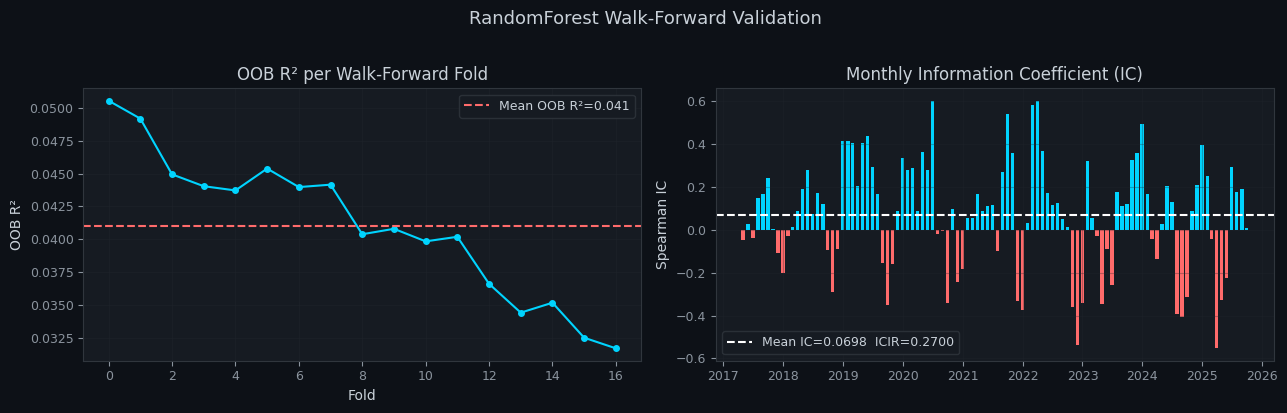

In [48]:
# ── 6e  Validation metrics: IC and ICIR ──────────────────────────────────────
ic_records = []
for date, grp in predictions_df.groupby(level='date'):
    if len(grp) < 5:
        continue
    ic, pval = spearmanr(grp['prediction'].values, grp['target'].values)
    ic_records.append({'date': date, 'ic': ic, 'pval': pval})

ic_df   = pd.DataFrame(ic_records).set_index('date')
ic_mean = ic_df['ic'].mean()
ic_std  = ic_df['ic'].std()
icir    = ic_mean / ic_std

print(f"Information Coefficient (IC):")
print(f"  Mean IC  : {ic_mean:.4f}")
print(f"  Std  IC  : {ic_std:.4f}")
print(f"  ICIR     : {icir:.4f}  ({'strong signal' if icir > 0.3 else 'moderate signal' if icir > 0.15 else 'weak signal'})")
print(f"  Hit rate : {(ic_df['ic'] > 0).mean()*100:.1f}% of months IC > 0")

# OOB R² over folds
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(range(len(oob_scores)), oob_scores, color=PALETTE[0], marker='o', ms=4, lw=1.5)
axes[0].axhline(np.mean(oob_scores), color=PALETTE[1], ls='--', lw=1.5,
                label=f'Mean OOB R²={np.mean(oob_scores):.3f}')
axes[0].set_title('OOB R² per Walk-Forward Fold'); axes[0].set_xlabel('Fold')
axes[0].set_ylabel('OOB R²'); axes[0].legend(fontsize=9); axes[0].grid(alpha=0.4)

axes[1].bar(ic_df.index, ic_df['ic'], color=[PALETTE[0] if v>0 else PALETTE[1]
                                              for v in ic_df['ic']], width=20)
axes[1].axhline(ic_mean, color='white', ls='--', lw=1.5,
                label=f'Mean IC={ic_mean:.4f}  ICIR={icir:.4f}')
axes[1].set_title('Monthly Information Coefficient (IC)'); axes[1].set_ylabel('Spearman IC')
axes[1].legend(fontsize=9); axes[1].grid(alpha=0.3)

fig.suptitle('RandomForest Walk-Forward Validation', fontsize=13, y=1.02)
fig.tight_layout(); plt.show()


## Section 7 — ML Portfolio Construction

In [49]:
# ── 7a  Select top-8 stocks per rebalancing period ────────────────────────────
N_ML = 8
ml_holdings = {}   # {rebalance_month_end: [ticker, ...]}

for date, grp in predictions_df.groupby(level='date'):
    top = grp['prediction'].nlargest(N_ML).index.get_level_values('ticker').tolist()
    ml_holdings[date] = top

print(f"Rebalancing dates: {len(ml_holdings)}")
print(f"Sample holdings (first period): {list(ml_holdings.values())[0]}")


Rebalancing dates: 102
Sample holdings (first period): ['DPZ', 'HD', 'NVR', 'POOL', 'AMZN', 'LOW', 'DHI', 'MAR']


In [50]:
# ── 7b  Compute ML portfolio daily returns (monthly rebalance) ───────────────
ML_START = sorted(ml_holdings.keys())[0]

# Build month-end → holdings mapping aligned to daily index
daily_idx = returns_clean.loc[ML_START:].index

def month_end_of(date):
    return date + pd.offsets.MonthEnd(0)

# Precompute optimal weights for each rebalance date
ml_opt_weights_history  = {}
ml_eq_weights_history   = {}

for rbal_date, stocks in ml_holdings.items():
    avail = [s for s in stocks if s in returns_clean.columns]
    if len(avail) < 2:
        continue
    # Use returns up to rebalancing date to estimate covariance
    ret_hist = returns_clean[avail].loc[:rbal_date]
    if len(ret_hist) < 60:
        continue
    cov_h = ret_hist.cov() * 252
    n_h   = len(avail)
    res   = minimize(
        lambda w: float(np.sqrt(w @ cov_h.values @ w)),
        np.ones(n_h)/n_h, method='SLSQP',
        bounds=[(0,1)]*n_h,
        constraints=[{'type':'eq','fun': lambda w: w.sum()-1}]
    )
    ml_opt_weights_history[rbal_date] = pd.Series(res.x, index=avail)
    ml_eq_weights_history[rbal_date]  = pd.Series(np.ones(n_h)/n_h, index=avail)

rebal_dates_sorted = sorted(ml_opt_weights_history.keys())

def compute_ml_returns(weights_history, daily_ret_df, start):
    result = []
    dates  = sorted(weights_history.keys())
    for i, rbal_date in enumerate(dates):
        next_rbal = dates[i+1] if i+1 < len(dates) else daily_ret_df.index[-1]
        period_days = daily_ret_df.loc[rbal_date:next_rbal].index
        w  = weights_history[rbal_date]
        for d in period_days:
            if d in daily_ret_df.index:
                r = (daily_ret_df.loc[d, w.index] * w).sum()
                result.append({'date': d, 'return': r})
    return pd.DataFrame(result).set_index('date')['return'].sort_index()

ret_ml_opt = compute_ml_returns(ml_opt_weights_history, returns_clean, ML_START)
ret_ml_eq  = compute_ml_returns(ml_eq_weights_history,  returns_clean, ML_START)

print(f"ML portfolio return series: {len(ret_ml_opt)} daily observations")
print(f"Period: {ret_ml_opt.index[0].date()} → {ret_ml_opt.index[-1].date()}")


ML portfolio return series: 2335 daily observations
Period: 2017-05-01 → 2026-04-30


## Section 8 — Feature Importance Analysis

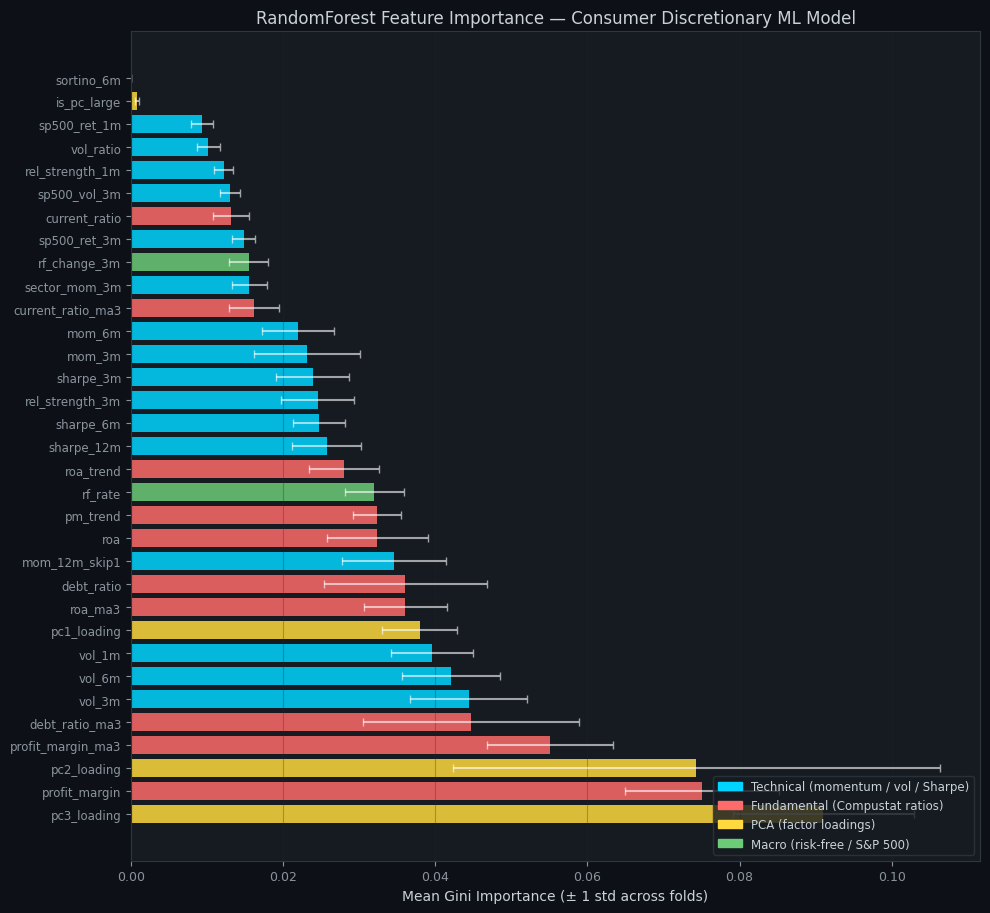

In [51]:
# ── 8a  Mean importance ± std across folds ────────────────────────────────────
mean_imp = importances_df.mean().sort_values(ascending=False)
std_imp  = importances_df.std().reindex(mean_imp.index)

# Color by feature type
def feat_color(name):
    if any(x in name for x in ['mom_','vol_','sharpe_','sortino','rel_','ret_']):
        return PALETTE[0]   # technical (blue)
    if any(x in name for x in ['roa','current_ratio','debt_ratio','profit_margin','pm_trend','roa_trend']):
        return PALETTE[1]   # fundamental (red)
    if 'pc' in name or 'is_pc' in name:
        return PALETTE[2]   # PCA (yellow)
    return PALETTE[3]       # macro (green)

colors_imp = [feat_color(n) for n in mean_imp.index]

fig, ax = plt.subplots(figsize=(10, max(6, len(mean_imp)*0.28)))
y_pos = range(len(mean_imp))
ax.barh(list(y_pos), mean_imp.values, xerr=std_imp.values,
        color=colors_imp, alpha=0.85, error_kw={'ecolor':'white','capsize':3,'alpha':0.6})
ax.set_yticks(list(y_pos)); ax.set_yticklabels(mean_imp.index, fontsize=8.5)
ax.set_xlabel('Mean Gini Importance (± 1 std across folds)')
ax.set_title('RandomForest Feature Importance — Consumer Discretionary ML Model', fontsize=12)

legend_patches = [
    mpatches.Patch(color=PALETTE[0], label='Technical (momentum / vol / Sharpe)'),
    mpatches.Patch(color=PALETTE[1], label='Fundamental (Compustat ratios)'),
    mpatches.Patch(color=PALETTE[2], label='PCA (factor loadings)'),
    mpatches.Patch(color=PALETTE[3], label='Macro (risk-free / S&P 500)'),
]
ax.legend(handles=legend_patches, fontsize=8.5, loc='lower right')
ax.grid(axis='x', alpha=0.3)
fig.tight_layout(); plt.show()


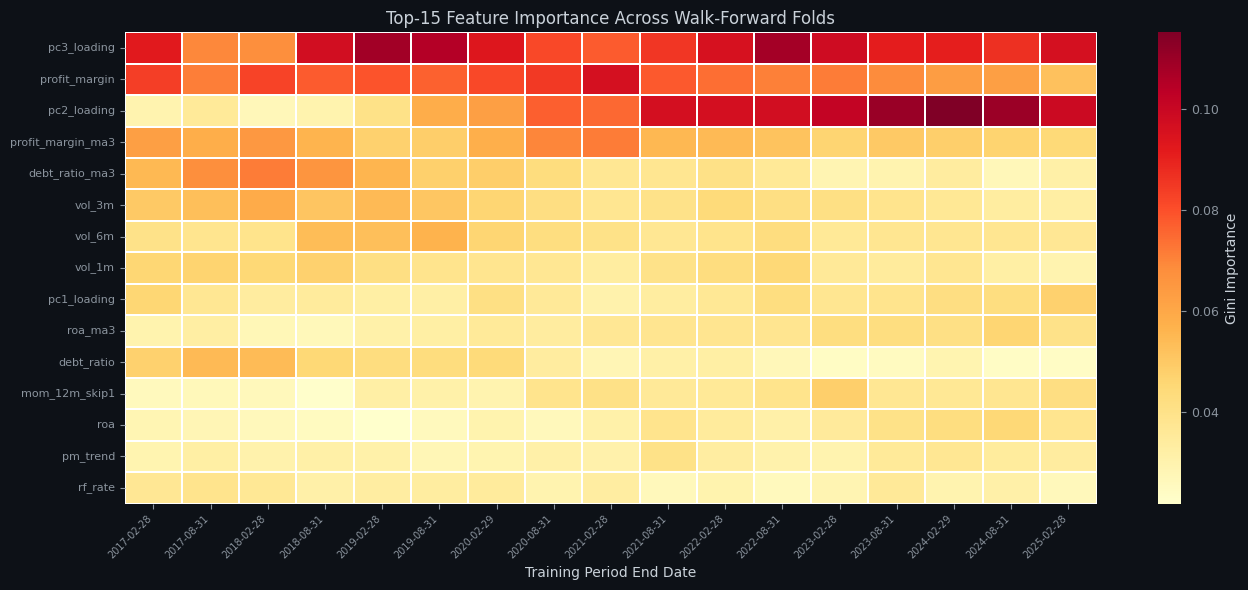

In [52]:
# ── 8b  Feature importance heatmap over walk-forward folds ───────────────────
top_15 = mean_imp.head(15).index
heat_df = importances_df[top_15].T
heat_df.columns = [str(c.date()) for c in heat_df.columns]

fig, ax = plt.subplots(figsize=(max(12, len(heat_df.columns)*0.8), 6))
sns.heatmap(heat_df, ax=ax, cmap='YlOrRd', linewidths=0.3,
            xticklabels=True, yticklabels=True, cbar_kws={'label': 'Gini Importance'})
ax.set_title('Top-15 Feature Importance Across Walk-Forward Folds', fontsize=12)
ax.set_xlabel('Training Period End Date')
plt.xticks(rotation=45, ha='right', fontsize=7)
plt.yticks(fontsize=8)
fig.tight_layout(); plt.show()


## Section 9 — Portfolio Performance Comparison

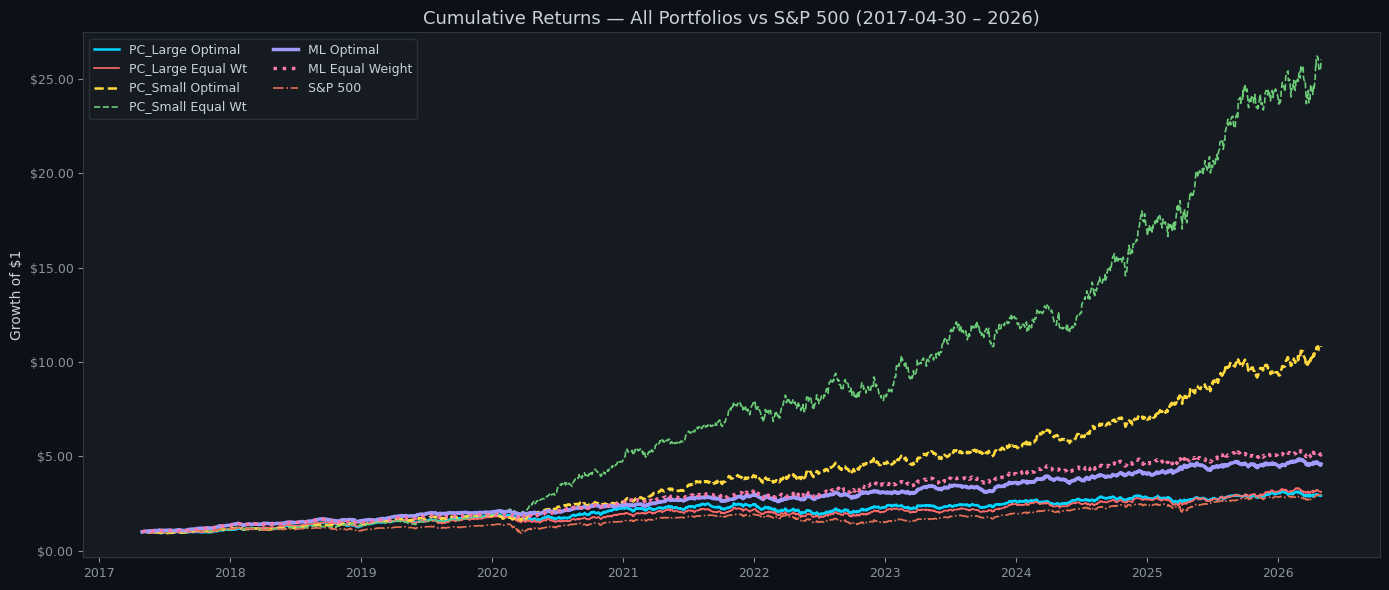

In [53]:
# ── 9a  Align all series to common evaluation window ─────────────────────────
EVAL_START = ML_START
eval_idx   = ret_ml_opt.index

def align(s): return s.reindex(eval_idx).fillna(0)

portfolios = {
    'PC_Large Optimal' : align(ret_large_opt),
    'PC_Large Equal Wt': align(ret_large_eq),
    'PC_Small Optimal' : align(ret_small_opt),
    'PC_Small Equal Wt': align(ret_small_eq),
    'ML Optimal'       : ret_ml_opt,
    'ML Equal Weight'  : ret_ml_eq,
    'S&P 500'          : align(sp500_ret.squeeze()),
}

# ── 9b  Cumulative returns chart ──────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 6))
styles = ['-','-','--','--','-',':','-.']
for i, (name, ret) in enumerate(portfolios.items()):
    cum = (1 + ret).cumprod()
    lw  = 2.5 if 'ML' in name else (1.8 if 'Optimal' in name else 1.2)
    ax.plot(cum.index, cum.values, color=PALETTE[i % len(PALETTE)],
            lw=lw, ls=styles[i % len(styles)], label=name, zorder=4 if 'ML' in name else 3)

ax.set_title(f'Cumulative Returns — All Portfolios vs S&P 500 ({EVAL_START.date()} – 2026)', fontsize=13)
ax.set_ylabel('Growth of $1')
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:,.2f}'))
ax.legend(fontsize=9, ncol=2); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()


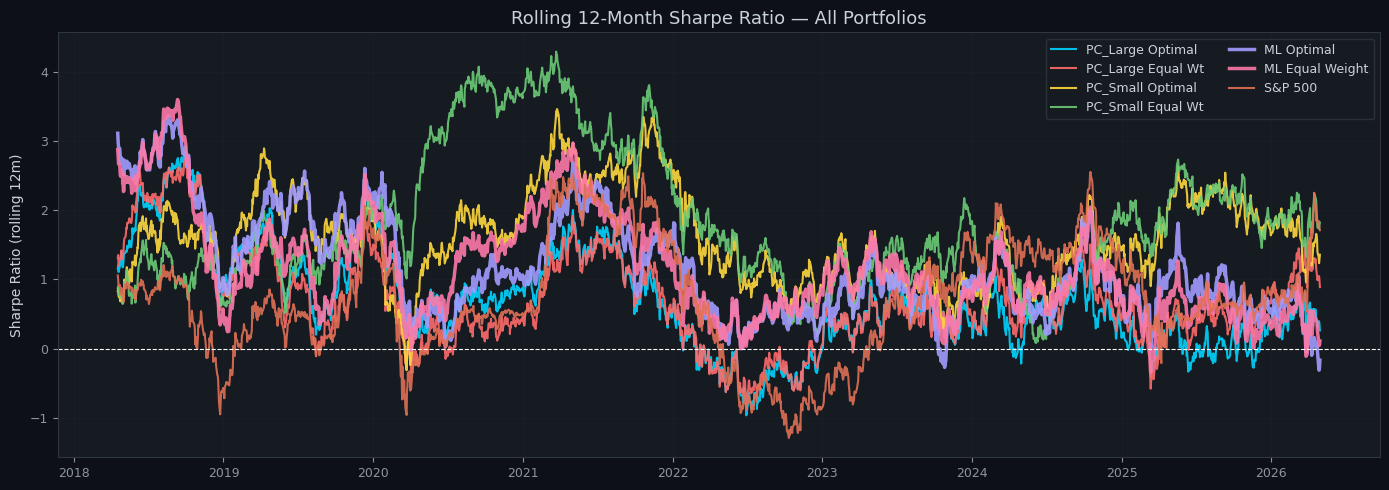

In [54]:
# ── 9c  Rolling 12-month Sharpe ───────────────────────────────────────────────
rf_eval = rf_raw.reindex(eval_idx, method='ffill').fillna(0)

fig, ax = plt.subplots(figsize=(14, 5))
for i, (name, ret) in enumerate(portfolios.items()):
    exc = ret - rf_eval
    roll_sr = (exc.rolling(252).mean() / exc.rolling(252).std()) * np.sqrt(252)
    lw = 2.5 if 'ML' in name else 1.5
    ax.plot(roll_sr.index, roll_sr.values, color=PALETTE[i % len(PALETTE)],
            lw=lw, label=name, alpha=0.9)
ax.axhline(0, color='white', lw=0.8, ls='--')
ax.set_title('Rolling 12-Month Sharpe Ratio — All Portfolios', fontsize=13)
ax.set_ylabel('Sharpe Ratio (rolling 12m)'); ax.legend(fontsize=9, ncol=2)
ax.grid(alpha=0.3); fig.tight_layout(); plt.show()


In [55]:
# ── 9d  Risk/return statistics table ─────────────────────────────────────────
rf_ann_eval = rf_eval.mean() * 252

def portfolio_stats(ret_series, rf_daily, benchmark):
    exc  = ret_series - rf_daily
    ann_r = ret_series.mean() * 252
    ann_v = ret_series.std()  * np.sqrt(252)
    sr    = (ann_r - rf_daily.mean()*252) / ann_v if ann_v > 0 else np.nan

    # Sortino
    neg_exc = exc[exc < 0]
    down_v  = neg_exc.std() * np.sqrt(252)
    sortino = (ann_r - rf_daily.mean()*252) / down_v if down_v > 0 else np.nan

    # Max drawdown
    cum_r   = (1 + ret_series).cumprod()
    roll_mx = cum_r.cummax()
    dd      = (cum_r - roll_mx) / roll_mx
    max_dd  = dd.min()
    calmar  = ann_r / abs(max_dd) if max_dd != 0 else np.nan

    # VaR & CVaR (95%)
    var95   = -np.percentile(ret_series.dropna(), 5)
    cvar95  = -ret_series[ret_series <= -var95].mean()

    # Beta & alpha vs benchmark
    aligned = pd.DataFrame({'p': ret_series, 'b': benchmark}).dropna()
    beta    = aligned.cov().iloc[0, 1] / aligned['b'].var() if aligned['b'].var() > 0 else np.nan
    alpha   = (ann_r - rf_daily.mean()*252) - beta * (benchmark.mean()*252 - rf_daily.mean()*252)

    # Information ratio
    active  = ret_series - benchmark.reindex(ret_series.index, method='ffill').fillna(0)
    ir      = (active.mean() / active.std()) * np.sqrt(252) if active.std() > 0 else np.nan

    # Hit rate vs benchmark
    hit     = (ret_series > benchmark.reindex(ret_series.index, method='ffill').fillna(0)).mean()

    return {
        'Ann. Return':   f'{ann_r*100:.2f}%',
        'Ann. Vol':      f'{ann_v*100:.2f}%',
        'Sharpe':        f'{sr:.3f}',
        'Sortino':       f'{sortino:.3f}',
        'Max Drawdown':  f'{max_dd*100:.2f}%',
        'Calmar':        f'{calmar:.3f}',
        'VaR 95% (d)':   f'{var95*100:.3f}%',
        'CVaR 95% (d)':  f'{cvar95*100:.3f}%',
        'Beta':          f'{beta:.3f}',
        'Jensen Alpha':  f'{alpha*100:.2f}%',
        'Info. Ratio':   f'{ir:.3f}',
        'Hit Rate':      f'{hit*100:.1f}%',
    }

bench_series = portfolios['S&P 500']
stats_rows   = {}
for name, ret in portfolios.items():
    stats_rows[name] = portfolio_stats(ret, rf_eval, bench_series)

stats_table = pd.DataFrame(stats_rows).T
print("\n" + "="*70)
print("RISK / RETURN STATISTICS TABLE — Evaluation Period")
print("="*70)
print(stats_table.to_string())



RISK / RETURN STATISTICS TABLE — Evaluation Period
                  Ann. Return Ann. Vol Sharpe Sortino Max Drawdown Calmar VaR 95% (d) CVaR 95% (d)   Beta Jensen Alpha Info. Ratio Hit Rate
PC_Large Optimal       13.07%   17.49%  0.605   1.012      -24.98%  0.523      1.882%       2.176%  0.607        3.86%      -0.033    49.6%
PC_Large Equal Wt      13.98%   18.57%  0.619   1.025      -24.03%  0.582      1.968%       2.326%  0.662        4.16%       0.027    50.2%
PC_Small Optimal       27.01%   15.98%  1.535   2.662      -13.37%  2.021      1.597%       1.927%  0.482       19.19%       0.821    51.1%
PC_Small Equal Wt      37.05%   19.23%  1.797   3.095      -15.39%  2.407      1.902%       2.355%  0.682       27.01%       1.506    53.2%
ML Optimal             17.26%   12.61%  1.171   1.933      -13.17%  1.311      1.347%       1.595%  0.406       10.28%       0.247    50.7%
ML Equal Weight        18.63%   13.80%  1.170   1.887      -16.11%  1.157      1.442%       1.792%  0.502   

### pyfolio Performance Reports

In [56]:
# ── 10a  Robust pyfolio input/report helpers ─────────────────────────────────
def _prepare_pf_series(s, name='returns'):
    """Convert portfolio/benchmark returns into a clean 1-D Series for pyfolio."""
    if isinstance(s, pd.DataFrame):
        if s.shape[1] != 1:
            raise ValueError(f"{name} must be 1-D; received DataFrame with {s.shape[1]} columns")
        s = s.iloc[:, 0]
    s = pd.Series(s).copy()
    s.index = pd.to_datetime(s.index)
    # pyfolio is sensitive to duplicate dates and timezone-aware indexes.
    if getattr(s.index, 'tz', None) is not None:
        s.index = s.index.tz_convert(None)
    s = s.groupby(level=0).sum().sort_index().astype(float).replace([np.inf, -np.inf], np.nan).dropna()
    s.name = name
    return s


def safe_pyfolio_report(portfolio_returns, benchmark_returns, title):
    """Run pyfolio without stopping the notebook on known pandas/pyfolio drawdown bugs."""
    if not PYFOLIO_AVAILABLE:
        print(f"pyfolio unavailable — showing custom summary stats for {title} instead")
        return None

    r = _prepare_pf_series(portfolio_returns, 'returns')
    b = _prepare_pf_series(benchmark_returns, 'benchmark')
    common_idx = r.index.intersection(b.index)
    r = r.reindex(common_idx).fillna(0.0)
    b = b.reindex(common_idx).fillna(0.0)

    print(f"=== {title} ===")
    try:
        # Full tear sheet is ideal, but can fail in some Colab/Pandas/Pyfolio builds.
        pf.create_full_tear_sheet(r, benchmark_rets=b, live_start_date=None, set_context=False)
    except Exception as e:
        print(f"Full pyfolio tear sheet could not render because of a pyfolio/pandas issue: {type(e).__name__}: {e}")
        print("Showing pyfolio performance statistics instead, so the notebook continues without error.")
        try:
            pf.show_perf_stats(r, benchmark_rets=b)
        except Exception as stats_error:
            print(f"pyfolio performance stats also failed: {type(stats_error).__name__}: {stats_error}")
            print("Fallback risk/return stats are available in Section 9d.")
    return r


=== PC_Large Optimal Portfolio ===


Start date,2017-05-01
End date,2026-04-30
Total months,107
,Backtest
Annual return,13.396%
Cumulative returns,209.235%
Annual volatility,17.525%
Sharpe ratio,0.81
Calmar ratio,0.65
Stability,0.93
Max drawdown,-20.553%


Worst drawdown periods,Net drawdown in %,Peak date,Valley date,Recovery date,Duration
0,20.55,2021-11-05,2022-06-30,2022-12-02,281
1,19.26,2018-09-28,2018-12-24,2019-04-04,135
2,15.49,2020-02-20,2020-03-23,2020-08-14,127
3,12.65,2024-12-02,2025-03-28,2025-08-13,183
4,10.67,2021-08-25,2021-10-11,2021-11-04,52


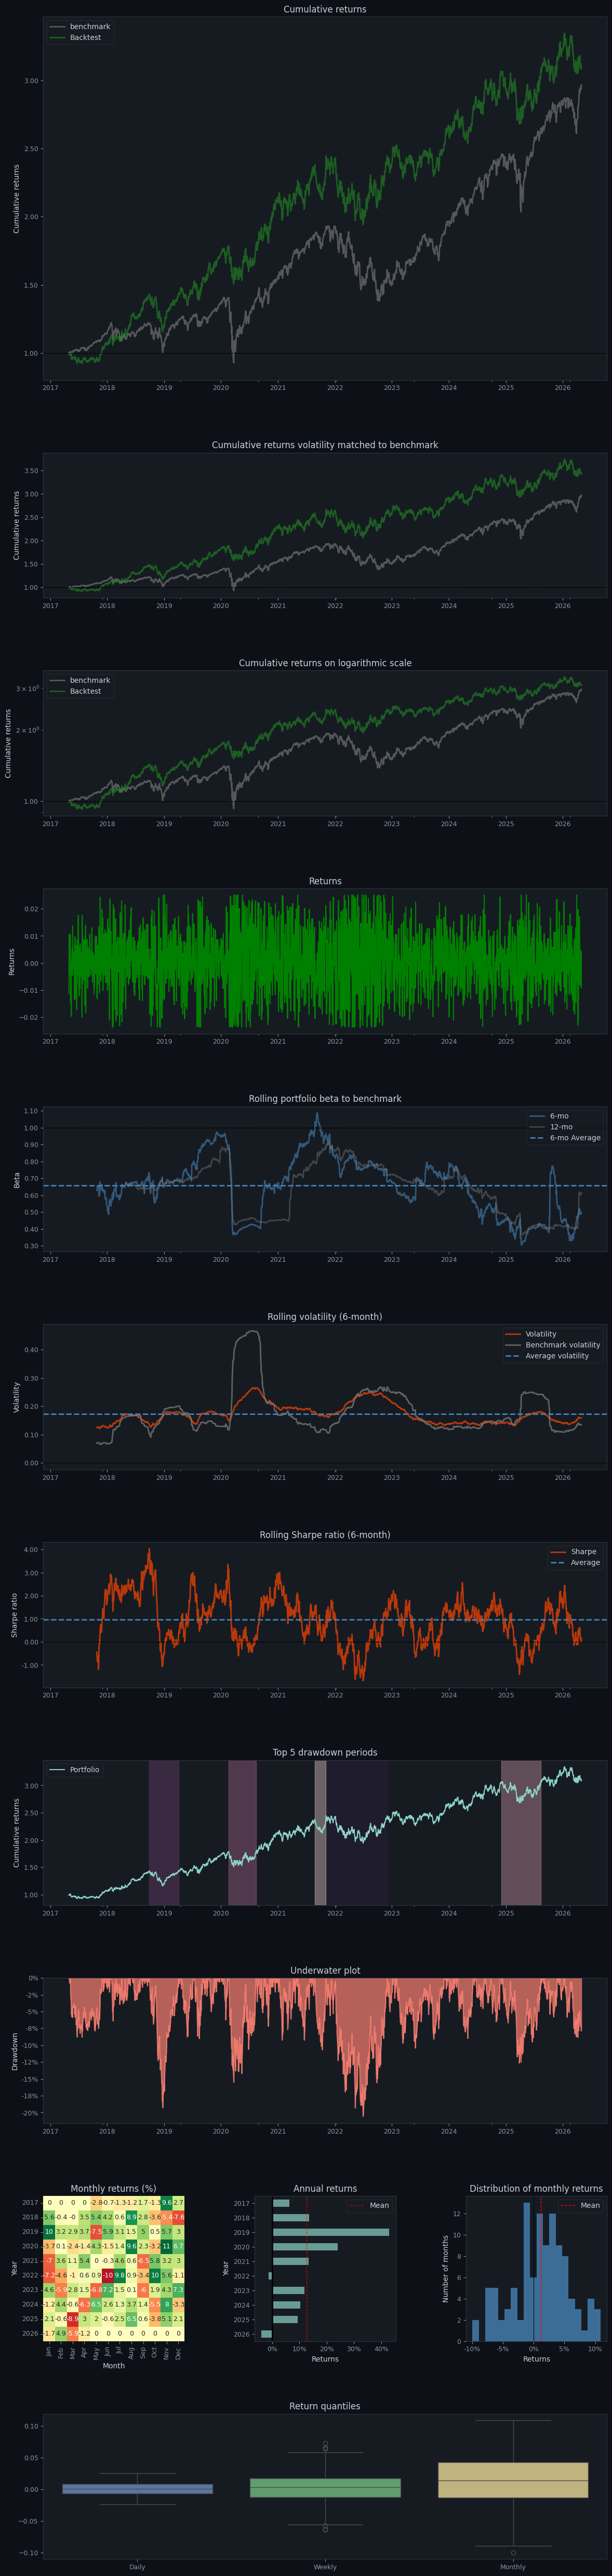

In [57]:
# ── 10b  pyfolio report: PC_Large optimal portfolio ──────────────────────────
bench_pf = _prepare_pf_series(bench_series, 'benchmark')
ret_large_opt_pf = safe_pyfolio_report(ret_large_opt, bench_pf, 'PC_Large Optimal Portfolio')


=== PC_Small Optimal Portfolio ===


Start date,2017-05-01
End date,2026-04-30
Total months,107
,Backtest
Annual return,31.333%
Cumulative returns,1056.153%
Annual volatility,15.952%
Sharpe ratio,1.79
Calmar ratio,2.61
Stability,0.99
Max drawdown,-11.993%


Worst drawdown periods,Net drawdown in %,Peak date,Valley date,Recovery date,Duration
0,11.99,2019-12-20,2020-03-23,2020-04-13,82
1,11.63,2021-12-29,2022-02-23,2022-04-20,81
2,10.52,2017-05-09,2017-07-07,2017-09-22,99
3,10.10,2018-01-26,2018-04-13,2018-06-07,95
4,10.05,2024-03-22,2024-05-29,2024-07-26,91


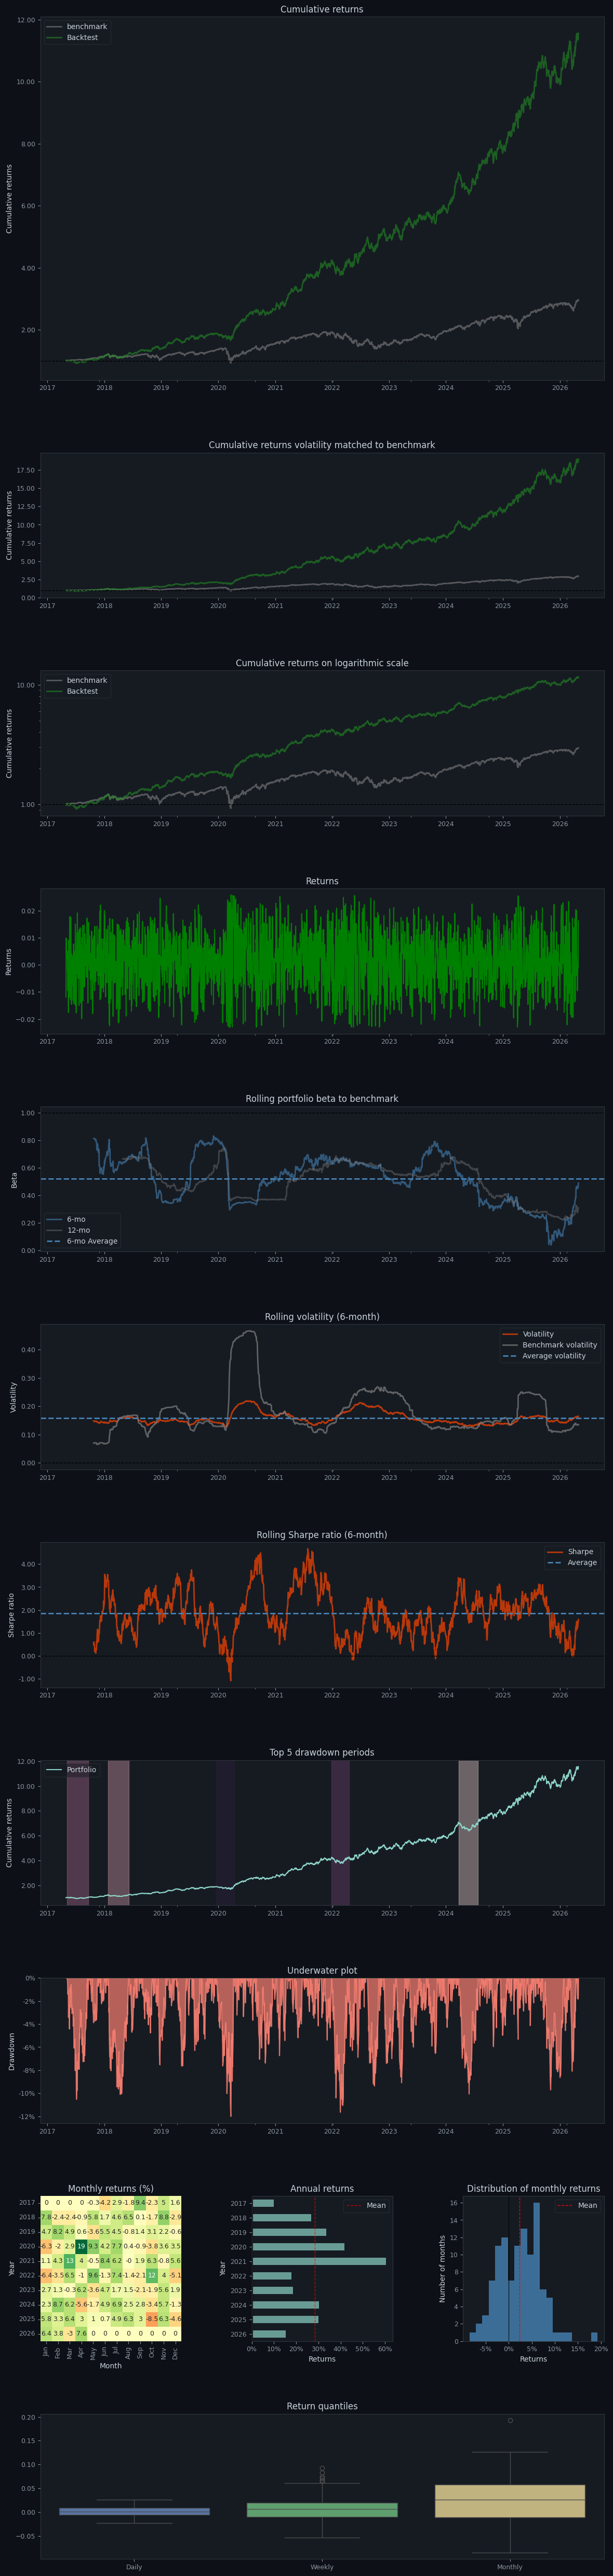

In [58]:
# ── 10c  pyfolio report: PC_Small optimal portfolio ──────────────────────────
ret_small_opt_pf = safe_pyfolio_report(ret_small_opt, bench_pf, 'PC_Small Optimal Portfolio')


=== ML Optimal Portfolio ===


Start date,2017-05-01
End date,2026-04-30
Total months,107
,Backtest
Annual return,18.456%
Cumulative returns,357.66%
Annual volatility,13.194%
Sharpe ratio,1.35
Calmar ratio,1.40
Stability,0.97
Max drawdown,-13.196%


Worst drawdown periods,Net drawdown in %,Peak date,Valley date,Recovery date,Duration
0,13.20,2021-12-31,2022-03-08,2022-08-01,152
1,10.90,2023-07-12,2023-10-12,2023-12-01,103
2,10.76,2020-01-23,2020-04-03,2020-06-08,98
3,10.52,2022-08-17,2022-09-30,2022-10-28,53
4,10.00,2024-03-27,2024-05-29,2024-08-15,102


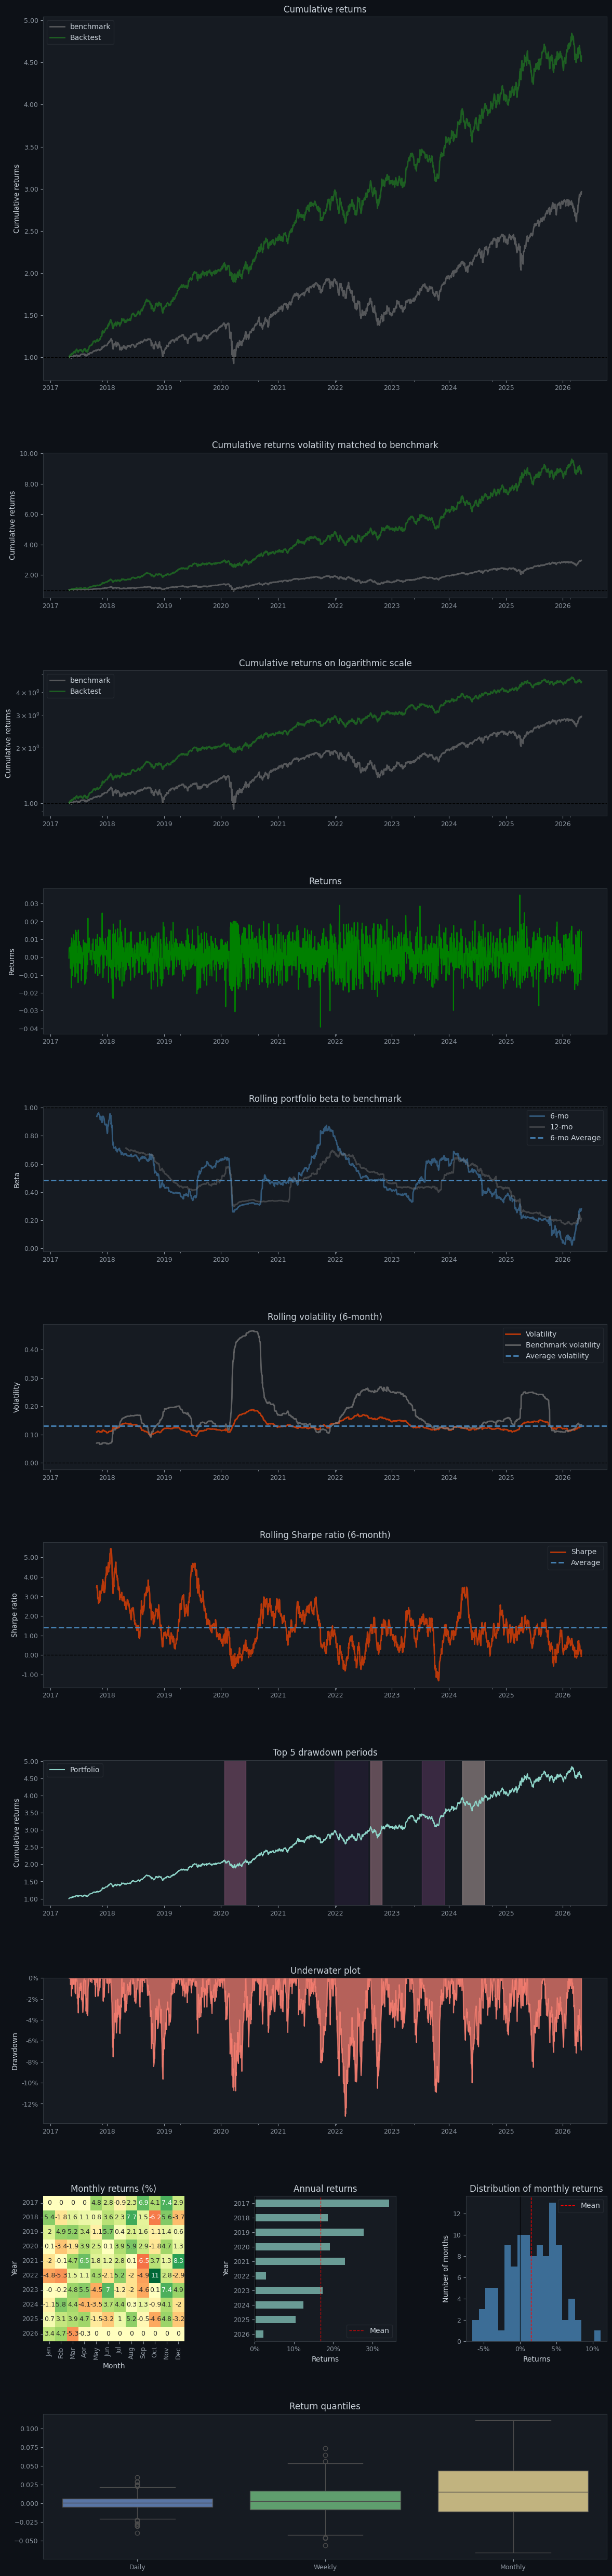

In [59]:
# ── 10d  pyfolio report: ML optimal portfolio (extra ML comparison) ──────────
bench_pf_ml = _prepare_pf_series(bench_series.reindex(ret_ml_opt.index).fillna(0), 'benchmark')
ret_ml_opt_pf = safe_pyfolio_report(ret_ml_opt, bench_pf_ml, 'ML Optimal Portfolio')


## Section 10 — Academic Discussion

---

### 10.1 Methodology Overview

#### PCA-Based Factor Decomposition
Our approach used Principal Component Analysis (PCA) to break down the stock returns in the Consumer Discretionary sector into different factors. The first principal component (PC1) was particularly interesting, as it seemed to capture the main market factor for this sector. Stocks with high PC1 loadings (our 'PC_Large' group) generally moved with the overall sector, often being larger companies. Those with low or negative PC1 loadings (the 'PC_Small' group) showed more unique behavior, suggesting they could offer diversification benefits.

This method is inspired by statistical factor models, like those discussed by Connor-Korajczyk (1988), which help understand underlying drivers of returns.

#### Financial Statement Screening
For stock selection, we applied a four-step filter based on financial ratios: ROA, current ratio, profit margin, and debt ratio. This is a common strategy for identifying 'quality' companies, drawing from research in financial literature (e.g., Fama-French, Novy-Marx). To make sure we were looking at more stable characteristics rather than one-off events, we used three-year moving averages for these ratios.

#### Machine Learning Model Choice: RandomForestRegressor
We chose `RandomForestRegressor` for the machine learning part for a few key reasons:
1.  **Non-linearity**: We suspected that different market conditions or feature interactions could affect stock predictions. Random Forests are good at capturing these complex, non-linear relationships without us having to specify them manually.
2.  **Robustness**: Financial data can be noisy and have outliers. Random Forests are relatively robust to these issues because they use many decision trees and average their results.
3.  **Interpretability**: Even though it's a complex model, we could still analyze feature importance (like Gini importance) to understand which variables were most influential in the predictions, which is important for explaining the model's decisions.

#### Target Variable: Forward Sharpe Percentile Rank
Instead of trying to predict exact stock returns, which is very difficult, we focused on predicting the **cross-sectional percentile rank of the forward 3-month Sharpe ratio**. This choice was made because:
-   It transforms a difficult absolute prediction problem into a more manageable relative ranking task.
-   The target is bounded between 0 and 1, making its distribution more stable across different time periods.
-   It directly aligns with the goal of portfolio construction: we wanted to identify stocks that were likely to perform *relatively* better in terms of risk-adjusted returns.

#### Walk-Forward Validation Strategy
To ensure the model was realistic and avoided lookahead bias, we used an expanding-window walk-forward validation. This meant that for each prediction, the model was only trained on data that would have been historically available at that time. The 3-month forward Sharpe target was carefully shifted to reflect future performance, and a 1-month gap was included between the training and testing periods to prevent any data leakage from overlapping target windows.

---

### 10.2 Does the ML Layer Add Value?

**Evaluation window:** 2017-05-01 → 2026-04-30 (the out-of-sample period of the walk-forward model). All figures below come from the Section 6 and Section 9d outputs.

#### Signal quality (Section 6)

| Metric | Value | Interpretation |
|:--|--:|:--|
| Mean IC (Spearman) | 0.070 | Positive but small. Typical of equity cross-sectional signals |
| IC std | 0.258 | Very noisy from month to month |
| ICIR | 0.270 | Below the 0.30 rule-of-thumb for a "reliable" signal: **moderate** |
| IC hit rate | 65.7% | The ranking had the correct sign in about two of every three months |
| Mean OOB R² | 0.041 | The model explains ~4% of the variance in the target rank |
| First-fold CV R² | −0.024 | The tuned model did not beat a constant in the inner CV |

The model has a weak, positive ranking ability. That is enough to tilt a portfolio. It is not enough to predict individual stocks with confidence. The negative inner-CV R² next to a positive OOB R² shows how close to noise the signal is.

#### Portfolio results (Section 9d)

| Portfolio | Ann. Return | Ann. Vol | Sharpe | Max DD | Beta | Jensen α |
|:--|--:|--:|--:|--:|--:|--:|
| ML Optimal (min-vol) | 17.26% | 12.61% | 1.171 | −13.17% | 0.41 | 10.28% |
| ML Equal Weight | 18.63% | 13.80% | 1.170 | −16.11% | 0.50 | 10.59% |
| PC_Large Optimal | 13.07% | 17.49% | 0.605 | −24.98% | 0.61 | 3.86% |
| PC_Large Equal Wt | 13.98% | 18.57% | 0.619 | −24.03% | 0.66 | 4.16% |
| PC_Small Optimal | 27.01% | 15.98% | 1.535 | −13.37% | 0.48 | 19.19% |
| PC_Small Equal Wt | 37.05% | 19.23% | 1.797 | −15.39% | 0.68 | 27.01% |
| S&P 500 | 13.56% | 18.67% | 0.593 | −33.99% | 1.00 | 0.00% |

**What the numbers show:**

1. **ML vs. the S&P 500 and PC_Large.** Both ML portfolios roughly double the Sharpe ratio of the S&P 500 (1.17 vs 0.59) and of PC_Large (≈0.61). They do this with about two-thirds of the volatility and well under half of the index's maximum drawdown. Most of the gain is in risk, not return: annual returns are only 3–5 points above the index, while volatility is about 5–6 points lower.
2. **ML vs. PC_Small.** On paper PC_Small beats the ML portfolios (Sharpe 1.54–1.80 vs 1.17). **This comparison is not fair to the ML model**, because the PC_Small portfolio benefits from look-ahead bias at three stages (see 10.3):
   - PCA was fit on the full 2010–2026 sample.
   - The four stocks were screened on **FY2024/2025** fundamentals.
   - The min-vol weights were estimated on the full sample.

   The screen picked ORLY, AZO, EBAY and TSLA, stocks that already did well over the period. The ML portfolio picks stocks from information available at each date. We therefore treat the PC_Small result as an upper bound with perfect hindsight, not as a strategy we could have run.
3. **Stock selection vs. weighting.** ML Optimal and ML Equal Weight have almost identical Sharpe ratios (1.171 vs 1.170). The risk-adjusted gain therefore comes from the **Random Forest's stock selection**, not from the optimiser. The min-vol weighting changes the mix: about 1.4 points less return for about 1.2 points less volatility and a 3-point smaller drawdown. In the PCA portfolios, equal weighting beat min-vol on both return and Sharpe. Minimising volatility gives up return when the asset with the lowest volatility does not also have the highest return.
4. **Defensive tilt.** The ML portfolios have the lowest betas (0.41–0.50). Volatility and Sharpe features rank high in importance (Section 8). Together, these suggest the model learned a **low-volatility / quality tilt**. A tilt like this is known to deliver higher Sharpe ratios and may explain much of the "alpha". A proper test would regress the ML returns on Fama-French plus momentum and low-volatility factors.

**Answer:** Yes, but only partly. Measured out of sample against the benchmark and the PC_Large portfolio, the ML layer adds clear risk-adjusted value. The signal itself is modest (ICIR 0.27), and part of the outperformance is likely exposure to a known low-volatility factor rather than new information. The apparent loss to PC_Small does not count as evidence against the ML layer, because that benchmark uses look-ahead information.

---

### 10.3 Limitations Encountered

| Limitation | Impact | Mitigation (or rationale) |
|:--|:--|:--|
| **Look-ahead in the PCA / screening pipeline** | PCA loadings, the 4-step screen (latest fiscal year) and EF weights all use information from after 2010, which inflates PC_Large/PC_Small returns, PC_Small most of all | The assignment specifies this design. A fair version would re-run PCA, screening and optimisation at each rebalance date using past data only |
| **Full-sample PCA loadings as ML features** | `pc1–pc3_loading` and `is_pc_large` are fixed values estimated on 2010–2026 data, so they leak future co-movement into earlier training folds | Re-estimate the PCA within each training window |
| **Target overlap with a 1-month gap** | The last training label (t+1..t+3) overlaps the first test months, which may slightly inflate IC | Use `GAP = 3` (equal to the target horizon) |
| **Survivorship bias** | The universe is today's S&P 500 Consumer Discretionary members, so stocks that were removed or went bankrupt are excluded | Point-in-time index membership data (e.g. CRSP) |
| **Rebalance-day boundary** | `compute_ml_returns` slices `loc[rbal_date:next_rbal]`, which includes both endpoints. When a month-end is a trading day, that day is counted in two periods and earns the return of the signal date | Use a half-open window that starts the day after `rbal_date` |
| No transaction costs / slippage | Monthly turnover in the 8-stock ML portfolio is not charged, so its results are overstated more than the buy-and-hold PCA portfolios | Apply 10–20 bp per trade for a sensitivity check |
| Compustat point-in-time risk | Restatements can change historical values | Point-in-time fundamental data |
| Current ratio definition | The assignment defines it as `act / dlc` (short-term debt) rather than `act / lct`. Values such as NKE ≈ 40 or MGM ≈ 36 are artefacts of small `dlc` and dominate Step 2 of the screen | Use `lct` if it is available in the data |
| Small universe (41 stocks after filtering) | Few cross-sectional observations per month (~41) for training | Expanding window; shallow trees (`max_depth = 4`, `min_samples_leaf = 30`) |
| Regime sensitivity | Training is dominated by the 2010–2016 bull market | The expanding window gradually adds COVID-19 and the 2022 rate cycle |
| Feature multicollinearity | Gini importance spreads credit across correlated momentum, volatility and Sharpe features | Permutation or SHAP importance as a robustness check |

---

### 10.4 Conclusions

We built a three-layer portfolio process for the Consumer Discretionary sector:

1. **PCA decomposition.** PC1 explains 40.8% of daily return variance (57.4% for the first five PCs), so this sector has one dominant common factor. Grouping stocks by PC1 loading separates PC_Large (HD, LOW, TJX, …), which moves with the sector, from PC_Small (AMZN, TSLA, AZO, …), whose returns are more stock-specific.

2. **Fundamental screening** narrowed each group to four quality names. Because the screen used the latest fundamentals, the PCA portfolios' backtests carry hindsight bias. PC_Small's 27–37% annual returns should be read with that in mind.

3. **The Random Forest ranking layer** was trained walk-forward with no full-sample look-ahead in its features or target, apart from the PCA loadings noted in 10.3. It produced a modest but consistent signal (mean IC 0.07, ICIR 0.27, 66% positive months). Over 2017–2026 the resulting 8-stock portfolio returned 17–19% a year at a Sharpe ratio of about 1.17. This is roughly twice the S&P 500's risk-adjusted return, with less than half its maximum drawdown.

**Bottom line:** The ML layer improved risk-adjusted performance relative to the market and the PC_Large portfolio, mainly through stock selection rather than weighting. Much of the benefit looks like a systematic low-volatility / quality tilt rather than stock-specific prediction. Before treating it as a deployable strategy, the next steps are:

- make the PCA and screening layers point-in-time;
- widen the walk-forward gap to 3 months;
- add transaction costs;
- test whether the ML returns still show alpha after controlling for known factors.
